# tPeak analysis from HDF5

Reads the HDF5 file made by `organize_to_hdf5` (for example `nan3.h5`), calculates the time to peak (tPeak) of each neuron's Ca and HyLight response (`tpeak_df`), and plots it with `dotplot_tpeak`.

Analysis:
- **tPeak** (`compute_tpeak_lowpass_filtered`): each trace is low-pass filtered (4 Hz, 4th-order Butterworth, zero-phase). The baseline is the median of the filtered trace in the 1 s before stimulus onset (stimulus onset is at 1 s). The peak is the largest positive baseline-corrected value from 0 to 15 s after stimulus onset. A trace counts as a responder if this peak is at least the sensor's minimum peak (Ca 0.12, HyLight 0.06 ΔF/F). For responders, `tpeak_s` is the peak time relative to stimulus onset; for non-responders it is NaN.
- **First depolarization** (same function): the first local maximum of the baseline-corrected slope of the filtered trace that is above 4 × the baseline slope noise, searched from 0 to 1 s after stimulus onset and before the peak. Stored as `t_first_depolarization_s`.
- **Table** (`tpeak_results_to_dataframe`): one row per neuron and sensor, with `tpeak_s`, `peak_dff`, `is_responder`, `t_first_depolarization_s` and related columns.
- **Statistics and plot** (`dotplot_tpeak`): the control genotypes are pooled. The notebook runs a Brown–Forsythe test, a Welch ANOVA and a post hoc test of each genotype against the pooled control (Dunnett, or a corrected fallback). It returns per-genotype and pooled summary tables of the means.
- **Sanity checks** (`plot_tpeak_sanity_checks`): shows each Ca and HyLight trace with the filtered trace, the peak-search window, tPeak and the first depolarization.

Data loading: `load_all_data_from_hdf5` reads the HDF5 file into a nested dictionary (`all_data`), grouping the flies by their `condition` metadata.

**How to use:** set `H5_FILE` in section 1, then run all cells.

In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Settings

In [40]:
H5_FILE = Path("your/path/here/BAY.h5")

# Compartments included in the tPeak table.
compartmentlist = ["m1", "m2", "m3", "m5", "m8", "m9", "m10", "lo1", "lo4"]

## 2. Load the data

In [41]:
def load_all_data_from_hdf5(h5_file):
    """
    Read the HDF5 file made by organize_to_hdf5 into a nested dictionary,
    grouping flies by their condition attribute:

    all_data = {
      '<condition>': {
        'folder': '<condition>',
        'series': {
          '251117_s7': {
            'frequency': <float or None>,
            'compartments': {
              'lo1': {'ca': DataFrame, 'hylight': DataFrame},   # rows = neurons, columns = time points
              ...
            }
          },
          ...
        }
      },
      ...
    }
    """
    all_data = {}
    with h5py.File(h5_file, "r") as f:
        for fly_id, fly in f.items():
            condition = fly.attrs["condition"]
            for compartment, comp in fly.items():
                folder_dict = all_data.setdefault(condition, {"folder": condition, "series": {}})
                sdict = folder_dict["series"].setdefault(
                    fly_id, {"frequency": None, "compartments": {}}
                )
                freq = float(comp.attrs.get("imaging_frequency", np.nan))
                if sdict["frequency"] is None and np.isfinite(freq):
                    sdict["frequency"] = freq

                comp_dict = sdict["compartments"].setdefault(compartment, {})
                for meas_type, dset in comp.items():
                    comp_dict[meas_type] = pd.DataFrame(dset[:])
    return all_data


def summarize_all_data(all_data):
    """Number of flies (series) and neurons per condition, compartment and sensor."""
    rows = []
    for condition, folder_dict in all_data.items():
        for series_key, sdict in folder_dict["series"].items():
            for compartment, meas in sdict["compartments"].items():
                for meas_type, df in meas.items():
                    rows.append({
                        "condition": condition,
                        "compartment": compartment,
                        "sensor": meas_type,
                        "series": series_key,
                        "n_neurons": df.shape[0],
                        "has_frequency": sdict["frequency"] is not None,
                    })
    df = pd.DataFrame(rows)
    if df.empty:
        return df
    return (df.groupby(["condition", "compartment", "sensor"])
              .agg(n_flies=("series", "nunique"),
                   n_neurons=("n_neurons", "sum"),
                   flies_without_frequency=("has_frequency", lambda s: int((~s).sum())))
              .reset_index())


def select_genotypes(all_data, genotypes=None):
    """
    Return all_data with only the listed conditions (genotypes).
    genotypes=None returns all conditions. Names must match exactly,
    including the special minus sign in names like "−Sugar".
    """
    if genotypes is None:
        return all_data
    if isinstance(genotypes, str):
        genotypes = [genotypes]
    missing = [g for g in genotypes if g not in all_data]
    if missing:
        print(f"Not found: {missing}. Available: {list(all_data)}")
    return {g: all_data[g] for g in genotypes if g in all_data}

In [42]:
all_data = load_all_data_from_hdf5(H5_FILE)
print(summarize_all_data(all_data).to_string())

  condition compartment   sensor  n_flies  n_neurons  flies_without_frequency
0   postBAY          m9       ca        6         23                        0
1   postBAY          m9  hylight        6         23                        0
2    preBAY          m9       ca        6         26                        0
3    preBAY          m9  hylight        6         26                        0


Check that every fly has an imaging frequency (the tPeak calculation needs it):

In [43]:
missing_frequency = [
    (g, s)
    for g, gdict in all_data.items()
    for s, sdict in gdict["series"].items()
    if sdict.get("frequency", None) is None
]

if missing_frequency:
    for g, s in missing_frequency:
        print("Missing frequency:", g, s)
else:
    print("All flies have an imaging frequency.")

All flies have an imaging frequency.


## 3. tPeak functions

In [44]:
import re
import numpy as np
from scipy.signal import butter, sosfiltfilt, find_peaks


def compute_tpeak_lowpass_filtered(
    all_data,
    stimulus_start_time=1.0,
    peak_search_window=(0.0, 10.0),
    lowpass_cutoff_hz=4.0,
    filter_order=4,
    target_hz=4.0,
    downsample_after_filtering=False,
    peak_direction="absolute",
    baseline_window=(-1.0, 0.0),
    sensor_min_peak=None,
    min_snr=4.0,
    # First-positive-inflection / depolarization settings
    inflection_search_window=None,
    inflection_min_slope=None,
    inflection_min_slope_snr=4.0,
    inflection_only_for_responders=True,
    inflection_must_precede_positive_peak=True,
    store_processed_traces=False,
):
    """
    Low-pass filter each trace and calculate both:

        1. Peak response and tPeak.
        2. Time to the first positive inflection point, used here as an
           estimate of the first depolarization.

    The first positive inflection point is defined as the first local maximum
    of the positive first derivative of the filtered trace. Equivalently, it
    is the first point on a rising response where curvature changes from
    concave-up to concave-down and the positive slope is maximal locally.

    The inflection-point slope must exceed a threshold based on either:

        inflection_min_slope
            A fixed slope threshold in trace units per second.

        inflection_min_slope_snr × baseline_slope_noise
            A noise-based slope threshold.

    When both are supplied, the larger threshold is used.

    Parameters
    ----------
    all_data : dict
        Nested data structure:

        all_data[genotype]["series"][series_name]["compartments"]
                [compartment][measurement_type]

        Each measurement type should contain a pandas DataFrame where:
            rows = individual traces
            columns = time points

    stimulus_start_time : float, default=1.0
        Stimulus onset time relative to the beginning of the recording.

    peak_search_window : tuple, default=(0.0, 10.0)
        Peak-search interval in seconds relative to stimulus onset.

    lowpass_cutoff_hz : float, default=4.0
        Butterworth low-pass cutoff frequency in Hz.

    filter_order : int, default=4
        Butterworth filter order.

    target_hz : float, default=4.0
        Approximate sampling frequency after optional downsampling.

    downsample_after_filtering : bool, default=False
        If True, downsample only after low-pass filtering.

    peak_direction : {"absolute", "positive", "negative"}
        Direction used to identify the candidate peak.

    baseline_window : tuple, default=(-1.0, 0.0)
        Baseline interval in seconds relative to stimulus onset.

    sensor_min_peak : dict, float, or None
        Fixed minimum response amplitude for responder classification.

    min_snr : float or None, default=4.0
        Minimum peak amplitude in multiples of baseline trace noise.

    inflection_search_window : tuple or None, default=None
        Search interval for the first positive inflection point, in seconds
        relative to stimulus onset. If None, peak_search_window is used.

    inflection_min_slope : dict, float, or None, default=None
        Fixed minimum positive slope in trace units per second. A dictionary
        may provide sensor-specific values, for example:

            inflection_min_slope={
                "ca": 0.02,
                "hylight": 0.005,
            }

    inflection_min_slope_snr : float or None, default=4.0
        Required positive slope as a multiple of robust baseline slope noise.
        Set to None to disable the slope-noise criterion.

    inflection_only_for_responders : bool, default=True
        If True, the inflection metric is reported only for traces classified
        as responders by the peak-response criteria.

    inflection_must_precede_positive_peak : bool, default=True
        If True and the detected peak is positive, only positive inflection
        points occurring at or before that positive peak are considered.

    store_processed_traces : bool, default=False
        If True, store the exact processed trace and time vector used for
        detection.

    Returns
    -------
    tpeak_results : dict
        Output matching the genotype, series, compartment, and measurement
        structure of all_data.

        Existing peak-related outputs are retained. Added outputs are:

            "t_first_positive_inflection_s"
                Time from stimulus onset to the first positive inflection.

            "t_first_depolarization_s"
                Alias of t_first_positive_inflection_s.

            "first_positive_inflection_time_s"
                Inflection time relative to recording start.

            "first_positive_inflection_dff"
                Filtered trace value at the inflection point.

            "first_positive_inflection_slope"
                Positive baseline-corrected slope at the inflection point,
                in trace units per second.

            "has_positive_inflection"
                True when a qualifying positive inflection was detected.

            "positive_inflection_slope_threshold"
                Final slope threshold applied to that trace.

            "baseline_slope_center"
                Median derivative during the baseline interval.

            "baseline_slope_noise"
                Robust derivative-noise estimate during baseline.
    """

    # ============================================================
    # Validate inputs
    # ============================================================

    if lowpass_cutoff_hz <= 0:
        raise ValueError(
            "lowpass_cutoff_hz must be greater than zero."
        )

    if filter_order < 1:
        raise ValueError(
            "filter_order must be at least 1."
        )

    if downsample_after_filtering:
        if target_hz is None or target_hz <= 0:
            raise ValueError(
                "target_hz must be greater than zero when "
                "downsample_after_filtering=True."
            )

    valid_peak_directions = {
        "absolute",
        "positive",
        "negative",
    }

    if peak_direction not in valid_peak_directions:
        raise ValueError(
            "peak_direction must be 'absolute', "
            "'positive', or 'negative'."
        )

    if len(peak_search_window) != 2:
        raise ValueError(
            "peak_search_window must contain two values: "
            "(start_time, end_time)."
        )

    if len(baseline_window) != 2:
        raise ValueError(
            "baseline_window must contain two values: "
            "(start_time, end_time)."
        )

    if inflection_search_window is None:
        inflection_search_window = peak_search_window

    if len(inflection_search_window) != 2:
        raise ValueError(
            "inflection_search_window must contain two values: "
            "(start_time, end_time)."
        )

    if min_snr is not None and min_snr < 0:
        raise ValueError(
            "min_snr must be non-negative or None."
        )

    if (
        inflection_min_slope_snr is not None
        and inflection_min_slope_snr < 0
    ):
        raise ValueError(
            "inflection_min_slope_snr must be non-negative or None."
        )

    def _validate_sensor_setting(
        setting,
        setting_name,
    ):
        if setting is None:
            return

        if np.isscalar(setting):
            if float(setting) < 0:
                raise ValueError(
                    f"{setting_name} must be non-negative."
                )

            return

        if isinstance(setting, dict):
            for value in setting.values():
                if value is not None and float(value) < 0:
                    raise ValueError(
                        f"All {setting_name} values must be "
                        "non-negative or None."
                    )

            return

        raise TypeError(
            f"{setting_name} must be a dictionary, scalar, or None."
        )

    _validate_sensor_setting(
        sensor_min_peak,
        "sensor_min_peak",
    )

    _validate_sensor_setting(
        inflection_min_slope,
        "inflection_min_slope",
    )

    # ============================================================
    # Helpers for sensor-specific settings
    # ============================================================

    def _normalize_measurement_name(value):
        return re.sub(
            r"[^a-z0-9]",
            "",
            str(value).lower(),
        )

    def _resolve_sensor_setting(
        measurement_type,
        setting,
    ):
        """
        Resolve a scalar or sensor-specific dictionary setting.
        """

        if setting is None:
            return None

        if np.isscalar(setting):
            return float(setting)

        normalized_measurement = _normalize_measurement_name(
            measurement_type
        )

        normalized_settings = {
            _normalize_measurement_name(key): value
            for key, value in setting.items()
        }

        # Direct match
        if normalized_measurement in normalized_settings:
            value = normalized_settings[
                normalized_measurement
            ]

            return (
                None
                if value is None
                else float(value)
            )

        # Common calcium aliases
        if normalized_measurement in {
            "ca",
            "calcium",
        }:
            for alias in (
                "ca",
                "calcium",
            ):
                if alias in normalized_settings:
                    value = normalized_settings[
                        alias
                    ]

                    return (
                        None
                        if value is None
                        else float(value)
                    )

        # Match names containing HyLight
        if "hylight" in normalized_measurement:
            for key, value in normalized_settings.items():
                if "hylight" in key:
                    return (
                        None
                        if value is None
                        else float(value)
                    )

        return None

    # ============================================================
    # Trace processing helpers
    # ============================================================

    def _interpolate_nans(x):
        """
        Linearly interpolate non-finite values before filtering.

        Values outside the finite portion are extended using the nearest
        finite value.
        """

        x = np.asarray(
            x,
            dtype=float,
        )

        finite = np.isfinite(
            x
        )

        if not np.any(finite):
            return x.copy()

        if np.all(finite):
            return x.copy()

        indices = np.arange(
            x.size
        )

        x_filled = x.copy()

        x_filled[~finite] = np.interp(
            indices[~finite],
            indices[finite],
            x[finite],
        )

        return x_filled

    def _lowpass_process_trace(
        x,
        orig_freq,
        cutoff_hz,
        order,
        target_hz_,
        downsample,
    ):
        """
        Apply a zero-phase Butterworth low-pass filter and optionally
        downsample afterward.
        """

        x = np.asarray(
            x,
            dtype=float,
        )

        n = x.size

        if n == 0:
            return (
                x.copy(),
                np.array([], dtype=float),
                float(orig_freq),
                1,
            )

        if orig_freq <= 0:
            raise ValueError(
                "Original sampling frequency must be greater than zero."
            )

        original_nyquist = (
            float(orig_freq) / 2.0
        )

        if cutoff_hz >= original_nyquist:
            raise ValueError(
                f"lowpass_cutoff_hz={cutoff_hz} Hz must be below "
                f"the original Nyquist frequency "
                f"({original_nyquist:.3f} Hz)."
            )

        # --------------------------------------------------------
        # Determine optional downsampling interval
        # --------------------------------------------------------

        if (
            downsample
            and orig_freq > target_hz_
        ):
            downsample_step = max(
                1,
                int(
                    round(
                        orig_freq
                        / float(target_hz_)
                    )
                ),
            )

        else:
            downsample_step = 1

        effective_frequency = (
            float(orig_freq)
            / downsample_step
        )

        if downsample_step > 1:
            downsampled_nyquist = (
                effective_frequency / 2.0
            )

            if cutoff_hz >= downsampled_nyquist:
                raise ValueError(
                    f"lowpass_cutoff_hz={cutoff_hz} Hz must be below "
                    f"the downsampled Nyquist frequency "
                    f"({downsampled_nyquist:.3f} Hz).\n"
                    f"Use a lower cutoff, increase target_hz, or set "
                    f"downsample_after_filtering=False."
                )

        sample_indices = np.arange(
            0,
            n,
            downsample_step,
        )

        # Entire trace is NaN
        if not np.any(
            np.isfinite(x)
        ):
            return (
                np.full(
                    sample_indices.size,
                    np.nan,
                    dtype=float,
                ),
                sample_indices
                / float(orig_freq),
                effective_frequency,
                downsample_step,
            )

        x_filled = _interpolate_nans(
            x
        )

        # --------------------------------------------------------
        # Construct Butterworth filter
        # --------------------------------------------------------

        sos = butter(
            N=order,
            Wn=cutoff_hz,
            btype="lowpass",
            fs=float(orig_freq),
            output="sos",
        )

        default_padlen = 3 * (
            2 * len(sos)
            + 1
            - min(
                np.sum(
                    sos[:, 2] == 0
                ),
                np.sum(
                    sos[:, 5] == 0
                ),
            )
        )

        padlen = min(
            int(default_padlen),
            n - 1,
        )

        if n < 3 or padlen < 1:
            x_filtered = x_filled.copy()

        else:
            x_filtered = sosfiltfilt(
                sos,
                x_filled,
                padlen=padlen,
            )

        # --------------------------------------------------------
        # Downsample only after filtering
        # --------------------------------------------------------

        x_processed = x_filtered[
            sample_indices
        ]

        time_processed = (
            sample_indices
            / float(orig_freq)
        )

        return (
            x_processed,
            time_processed,
            effective_frequency,
            downsample_step,
        )

    # ============================================================
    # Robust baseline statistics
    # ============================================================

    def _calculate_baseline_statistics(
        values,
        relative_time,
        window,
    ):
        """
        Calculate the median and robust noise of values inside a window.

        Noise is estimated as:

            1.4826 × median absolute deviation

        If the MAD is zero, standard deviation is used as a fallback.
        """

        start, end = window

        values = np.asarray(
            values,
            dtype=float,
        )

        relative_time = np.asarray(
            relative_time,
            dtype=float,
        )

        mask = (
            np.isfinite(values)
            & np.isfinite(relative_time)
        )

        if start is not None:
            mask &= (
                relative_time
                >= float(start)
            )

        if end is not None:
            mask &= (
                relative_time
                < float(end)
            )

        baseline_values = values[
            mask
        ]

        if baseline_values.size == 0:
            return (
                0.0,
                np.nan,
                0,
            )

        center = float(
            np.nanmedian(
                baseline_values
            )
        )

        mad = float(
            np.nanmedian(
                np.abs(
                    baseline_values
                    - center
                )
            )
        )

        noise = (
            1.4826
            * mad
        )

        if (
            noise == 0
            and baseline_values.size > 1
        ):
            noise = float(
                np.nanstd(
                    baseline_values,
                    ddof=1,
                )
            )

        return (
            center,
            noise,
            int(
                baseline_values.size
            ),
        )

    # ============================================================
    # Peak detection
    # ============================================================

    def _find_peak_in_window(
        trace,
        recording_time,
        stimulus_start,
        search_window,
        direction,
        baseline_window_,
        min_peak_abs_dff,
        min_snr_,
    ):
        """
        Find the candidate peak and determine responder status.
        """

        trace = np.asarray(
            trace,
            dtype=float,
        )

        recording_time = np.asarray(
            recording_time,
            dtype=float,
        )

        empty_result = (
            np.nan,   # peak_dff
            np.nan,   # peak_abs_dff
            np.nan,   # peak_from_baseline_dff
            np.nan,   # peak_abs_from_baseline_dff
            np.nan,   # tpeak_s
            np.nan,   # peak_time_s
            None,     # detected_direction
            False,    # is_responder
            np.nan,   # response_threshold
            np.nan,   # baseline_center
            np.nan,   # baseline_noise
            np.nan,   # response_snr
        )

        if trace.size == 0:
            return empty_result

        if trace.size != recording_time.size:
            raise ValueError(
                "Trace and time arrays must have equal lengths."
            )

        relative_time = (
            recording_time
            - float(stimulus_start)
        )

        # --------------------------------------------------------
        # Baseline center and noise
        # --------------------------------------------------------

        (
            baseline_center,
            baseline_noise,
            _,
        ) = _calculate_baseline_statistics(
            values=trace,
            relative_time=relative_time,
            window=baseline_window_,
        )

        baseline_corrected_trace = (
            trace
            - baseline_center
        )

        # --------------------------------------------------------
        # Select peak-search interval
        # --------------------------------------------------------

        window_start, window_end = (
            search_window
        )

        search_mask = (
            np.isfinite(trace)
            & np.isfinite(relative_time)
        )

        if window_start is not None:
            search_mask &= (
                relative_time
                >= float(window_start)
            )

        if window_end is not None:
            search_mask &= (
                relative_time
                <= float(window_end)
            )

        candidate_indices = np.flatnonzero(
            search_mask
        )

        if candidate_indices.size == 0:
            return (
                np.nan,
                np.nan,
                np.nan,
                np.nan,
                np.nan,
                np.nan,
                None,
                False,
                np.nan,
                baseline_center,
                baseline_noise,
                np.nan,
            )

        candidate_response_values = (
            baseline_corrected_trace[
                candidate_indices
            ]
        )

        # --------------------------------------------------------
        # Identify candidate peak relative to baseline
        # --------------------------------------------------------

        if direction == "absolute":
            local_peak_idx = int(
                np.argmax(
                    np.abs(
                        candidate_response_values
                    )
                )
            )

        elif direction == "positive":
            local_peak_idx = int(
                np.argmax(
                    candidate_response_values
                )
            )

        else:
            local_peak_idx = int(
                np.argmin(
                    candidate_response_values
                )
            )

        peak_idx = candidate_indices[
            local_peak_idx
        ]

        peak_dff = float(
            trace[peak_idx]
        )

        peak_abs_dff = float(
            abs(peak_dff)
        )

        peak_from_baseline_dff = float(
            baseline_corrected_trace[
                peak_idx
            ]
        )

        peak_abs_from_baseline_dff = float(
            abs(
                peak_from_baseline_dff
            )
        )

        candidate_peak_time_s = float(
            recording_time[
                peak_idx
            ]
        )

        candidate_tpeak_s = float(
            candidate_peak_time_s
            - stimulus_start
        )

        if peak_from_baseline_dff > 0:
            detected_direction = "positive"

        elif peak_from_baseline_dff < 0:
            detected_direction = "negative"

        else:
            detected_direction = "zero"

        # --------------------------------------------------------
        # Determine response threshold
        # --------------------------------------------------------

        threshold_candidates = []

        if min_peak_abs_dff is not None:
            threshold_candidates.append(
                float(
                    min_peak_abs_dff
                )
            )

        if (
            min_snr_ is not None
            and np.isfinite(
                baseline_noise
            )
        ):
            threshold_candidates.append(
                float(min_snr_)
                * float(baseline_noise)
            )

        thresholding_enabled = (
            len(threshold_candidates) > 0
        )

        if thresholding_enabled:
            response_threshold = float(
                max(
                    threshold_candidates
                )
            )

        else:
            response_threshold = 0.0

        # --------------------------------------------------------
        # Determine responder status
        # --------------------------------------------------------

        if not thresholding_enabled:
            is_responder = True

        elif direction == "absolute":
            is_responder = bool(
                peak_abs_from_baseline_dff
                >= response_threshold
            )

        elif direction == "positive":
            is_responder = bool(
                peak_from_baseline_dff
                >= response_threshold
            )

        else:
            is_responder = bool(
                peak_from_baseline_dff
                <= -response_threshold
            )

        # --------------------------------------------------------
        # Signal-to-noise ratio
        # --------------------------------------------------------

        if (
            np.isfinite(baseline_noise)
            and baseline_noise > 0
        ):
            response_snr = float(
                peak_abs_from_baseline_dff
                / baseline_noise
            )

        elif (
            baseline_noise == 0
            and peak_abs_from_baseline_dff > 0
        ):
            response_snr = np.inf

        else:
            response_snr = np.nan

        # tPeak is undefined for nonresponders
        if is_responder:
            tpeak_s = candidate_tpeak_s
            peak_time_s = candidate_peak_time_s

        else:
            tpeak_s = np.nan
            peak_time_s = np.nan

        return (
            peak_dff,
            peak_abs_dff,
            peak_from_baseline_dff,
            peak_abs_from_baseline_dff,
            tpeak_s,
            peak_time_s,
            detected_direction,
            is_responder,
            response_threshold,
            baseline_center,
            baseline_noise,
            response_snr,
        )

    # ============================================================
    # First positive inflection / depolarization detection
    # ============================================================

    def _find_first_positive_inflection(
        trace,
        recording_time,
        stimulus_start,
        search_window,
        baseline_window_,
        fixed_min_slope,
        min_slope_snr,
        allow_detection,
        positive_peak_time_s,
        restrict_to_positive_peak,
    ):
        """
        Find the first qualifying local maximum of the positive derivative.

        A local maximum in the first derivative is the numerical estimate
        of an inflection point on the rising trace.
        """

        trace = np.asarray(
            trace,
            dtype=float,
        )

        recording_time = np.asarray(
            recording_time,
            dtype=float,
        )

        empty_result = (
            np.nan,  # inflection_dff
            np.nan,  # inflection_slope
            np.nan,  # t_inflection_s
            np.nan,  # inflection_time_s
            False,   # has_inflection
            np.nan,  # slope_threshold
            np.nan,  # baseline_slope_center
            np.nan,  # baseline_slope_noise
        )

        if trace.size < 3:
            return empty_result

        if recording_time.size != trace.size:
            raise ValueError(
                "Trace and time arrays must have equal lengths."
            )

        relative_time = (
            recording_time
            - float(stimulus_start)
        )

        # Derivative in trace units per second.
        # np.gradient uses the actual recording time vector.
        slope = np.gradient(
            trace,
            recording_time,
        )

        # --------------------------------------------------------
        # Baseline slope center and noise
        # --------------------------------------------------------

        (
            baseline_slope_center,
            baseline_slope_noise,
            _,
        ) = _calculate_baseline_statistics(
            values=slope,
            relative_time=relative_time,
            window=baseline_window_,
        )

        slope_from_baseline = (
            slope
            - baseline_slope_center
        )

        # --------------------------------------------------------
        # Determine required positive-slope threshold
        # --------------------------------------------------------

        threshold_candidates = []

        if fixed_min_slope is not None:
            threshold_candidates.append(
                float(
                    fixed_min_slope
                )
            )

        if (
            min_slope_snr is not None
            and np.isfinite(
                baseline_slope_noise
            )
        ):
            threshold_candidates.append(
                float(min_slope_snr)
                * float(baseline_slope_noise)
            )

        if threshold_candidates:
            slope_threshold = float(
                max(
                    threshold_candidates
                )
            )

        else:
            slope_threshold = 0.0

        # Inflection detection may be restricted to responders.
        if not allow_detection:
            return (
                np.nan,
                np.nan,
                np.nan,
                np.nan,
                False,
                slope_threshold,
                baseline_slope_center,
                baseline_slope_noise,
            )

        # --------------------------------------------------------
        # Construct inflection-search mask
        # --------------------------------------------------------

        window_start, window_end = (
            search_window
        )

        search_mask = (
            np.isfinite(trace)
            & np.isfinite(recording_time)
            & np.isfinite(slope_from_baseline)
        )

        if window_start is not None:
            search_mask &= (
                relative_time
                >= float(window_start)
            )

        if window_end is not None:
            search_mask &= (
                relative_time
                <= float(window_end)
            )

        if (
            restrict_to_positive_peak
            and np.isfinite(
                positive_peak_time_s
            )
        ):
            search_mask &= (
                recording_time
                <= float(positive_peak_time_s)
            )

        # --------------------------------------------------------
        # Find local maxima in the positive first derivative
        # --------------------------------------------------------

        derivative_peak_indices, _ = find_peaks(
            slope_from_baseline,
            height=max(
                0.0,
                slope_threshold,
            ),
        )

        valid_indices = derivative_peak_indices[
            search_mask[
                derivative_peak_indices
            ]
        ]

        if valid_indices.size == 0:
            return (
                np.nan,
                np.nan,
                np.nan,
                np.nan,
                False,
                slope_threshold,
                baseline_slope_center,
                baseline_slope_noise,
            )

        # find_peaks returns indices in temporal order.
        inflection_idx = int(
            valid_indices[0]
        )

        inflection_dff = float(
            trace[
                inflection_idx
            ]
        )

        inflection_slope = float(
            slope_from_baseline[
                inflection_idx
            ]
        )

        inflection_time_s = float(
            recording_time[
                inflection_idx
            ]
        )

        t_inflection_s = float(
            inflection_time_s
            - stimulus_start
        )

        return (
            inflection_dff,
            inflection_slope,
            t_inflection_s,
            inflection_time_s,
            True,
            slope_threshold,
            baseline_slope_center,
            baseline_slope_noise,
        )

    # ============================================================
    # Main calculation
    # ============================================================

    tpeak_results = {}

    for genotype, geno_dict in all_data.items():

        tpeak_results[genotype] = {
            "series": {}
        }

        for series_name, series_dict in geno_dict[
            "series"
        ].items():

            freq = float(
                series_dict[
                    "frequency"
                ]
            )

            if freq <= 0:
                raise ValueError(
                    f"Invalid frequency for "
                    f"{genotype}, {series_name}: "
                    f"{freq}"
                )

            if (
                downsample_after_filtering
                and freq > target_hz
            ):
                downsample_step = max(
                    1,
                    int(
                        round(
                            freq
                            / float(target_hz)
                        )
                    ),
                )

            else:
                downsample_step = 1

            effective_frequency = (
                freq
                / downsample_step
            )

            series_output = {
                "frequency":
                    freq,

                "target_hz":
                    target_hz,

                "effective_frequency":
                    effective_frequency,

                "bin_size":
                    downsample_step,

                "downsample_step":
                    downsample_step,

                "processing_method":
                    "zero-phase Butterworth low-pass",

                "lowpass_cutoff_hz":
                    lowpass_cutoff_hz,

                "filter_order":
                    filter_order,

                "downsample_after_filtering":
                    downsample_after_filtering,

                "stimulus_start_time":
                    stimulus_start_time,

                "peak_search_window":
                    peak_search_window,

                "peak_direction":
                    peak_direction,

                "baseline_window":
                    baseline_window,

                "sensor_min_peak":
                    sensor_min_peak,

                "min_snr":
                    min_snr,

                "inflection_search_window":
                    inflection_search_window,

                "inflection_min_slope":
                    inflection_min_slope,

                "inflection_min_slope_snr":
                    inflection_min_slope_snr,

                "inflection_only_for_responders":
                    inflection_only_for_responders,

                "inflection_must_precede_positive_peak":
                    inflection_must_precede_positive_peak,

                "compartments": {},
            }

            for comp, comp_dict in series_dict[
                "compartments"
            ].items():

                compartment_output = {}

                for meas_type, df in comp_dict.items():

                    if not hasattr(
                        df,
                        "iterrows",
                    ):
                        raise TypeError(
                            f"Expected a pandas DataFrame for "
                            f"{genotype}, {series_name}, "
                            f"{comp}, {meas_type}; "
                            f"received {type(df)}."
                        )

                    fixed_min_peak = (
                        _resolve_sensor_setting(
                            measurement_type=meas_type,
                            setting=sensor_min_peak,
                        )
                    )

                    fixed_min_inflection_slope = (
                        _resolve_sensor_setting(
                            measurement_type=meas_type,
                            setting=inflection_min_slope,
                        )
                    )

                    # Existing peak outputs
                    peak_dff_list = []
                    peak_abs_dff_list = []

                    peak_from_baseline_list = []
                    peak_abs_from_baseline_list = []

                    tpeak_list = []
                    peak_time_list = []

                    detected_direction_list = []
                    is_responder_list = []

                    response_threshold_list = []
                    baseline_center_list = []
                    baseline_noise_list = []
                    response_snr_list = []

                    # Added positive-inflection outputs
                    inflection_dff_list = []
                    inflection_slope_list = []

                    t_inflection_list = []
                    inflection_time_list = []

                    has_inflection_list = []

                    inflection_slope_threshold_list = []
                    baseline_slope_center_list = []
                    baseline_slope_noise_list = []

                    processed_trace_list = []
                    processed_time_list = []

                    for _, row in df.iterrows():

                        trace = row.values.astype(
                            float
                        )

                        (
                            trace_processed,
                            time_processed,
                            _,
                            _,
                        ) = _lowpass_process_trace(
                            trace,
                            orig_freq=freq,
                            cutoff_hz=
                                lowpass_cutoff_hz,
                            order=filter_order,
                            target_hz_=
                                target_hz,
                            downsample=
                                downsample_after_filtering,
                        )

                        # ----------------------------------------
                        # Peak calculation
                        # ----------------------------------------

                        (
                            peak_dff,
                            peak_abs_dff,
                            peak_from_baseline_dff,
                            peak_abs_from_baseline_dff,
                            tpeak_s,
                            peak_time_s,
                            detected_direction,
                            is_responder,
                            response_threshold,
                            baseline_center,
                            baseline_noise,
                            response_snr,
                        ) = _find_peak_in_window(
                            trace=
                                trace_processed,

                            recording_time=
                                time_processed,

                            stimulus_start=
                                stimulus_start_time,

                            search_window=
                                peak_search_window,

                            direction=
                                peak_direction,

                            baseline_window_=
                                baseline_window,

                            min_peak_abs_dff=
                                fixed_min_peak,

                            min_snr_=
                                min_snr,
                        )

                        # ----------------------------------------
                        # First depolarization / inflection
                        # ----------------------------------------

                        if inflection_only_for_responders:
                            allow_inflection = (
                                is_responder
                            )

                        else:
                            allow_inflection = True

                        if detected_direction == "positive":
                            positive_peak_time_s = (
                                peak_time_s
                            )

                        else:
                            positive_peak_time_s = np.nan

                        (
                            inflection_dff,
                            inflection_slope,
                            t_inflection_s,
                            inflection_time_s,
                            has_inflection,
                            inflection_slope_threshold,
                            baseline_slope_center,
                            baseline_slope_noise,
                        ) = _find_first_positive_inflection(
                            trace=
                                trace_processed,

                            recording_time=
                                time_processed,

                            stimulus_start=
                                stimulus_start_time,

                            search_window=
                                inflection_search_window,

                            baseline_window_=
                                baseline_window,

                            fixed_min_slope=
                                fixed_min_inflection_slope,

                            min_slope_snr=
                                inflection_min_slope_snr,

                            allow_detection=
                                allow_inflection,

                            positive_peak_time_s=
                                positive_peak_time_s,

                            restrict_to_positive_peak=
                                inflection_must_precede_positive_peak,
                        )

                        # ----------------------------------------
                        # Store peak outputs
                        # ----------------------------------------

                        peak_dff_list.append(
                            peak_dff
                        )

                        peak_abs_dff_list.append(
                            peak_abs_dff
                        )

                        peak_from_baseline_list.append(
                            peak_from_baseline_dff
                        )

                        peak_abs_from_baseline_list.append(
                            peak_abs_from_baseline_dff
                        )

                        tpeak_list.append(
                            tpeak_s
                        )

                        peak_time_list.append(
                            peak_time_s
                        )

                        detected_direction_list.append(
                            detected_direction
                        )

                        is_responder_list.append(
                            is_responder
                        )

                        response_threshold_list.append(
                            response_threshold
                        )

                        baseline_center_list.append(
                            baseline_center
                        )

                        baseline_noise_list.append(
                            baseline_noise
                        )

                        response_snr_list.append(
                            response_snr
                        )

                        # ----------------------------------------
                        # Store inflection outputs
                        # ----------------------------------------

                        inflection_dff_list.append(
                            inflection_dff
                        )

                        inflection_slope_list.append(
                            inflection_slope
                        )

                        t_inflection_list.append(
                            t_inflection_s
                        )

                        inflection_time_list.append(
                            inflection_time_s
                        )

                        has_inflection_list.append(
                            has_inflection
                        )

                        inflection_slope_threshold_list.append(
                            inflection_slope_threshold
                        )

                        baseline_slope_center_list.append(
                            baseline_slope_center
                        )

                        baseline_slope_noise_list.append(
                            baseline_slope_noise
                        )

                        if store_processed_traces:
                            processed_trace_list.append(
                                trace_processed
                            )

                            processed_time_list.append(
                                time_processed
                            )

                    measurement_output = {
                        # Existing peak outputs
                        "peak_dff":
                            peak_dff_list,

                        "peak_abs_dff":
                            peak_abs_dff_list,

                        "peak_from_baseline_dff":
                            peak_from_baseline_list,

                        "peak_abs_from_baseline_dff":
                            peak_abs_from_baseline_list,

                        "tpeak_s":
                            tpeak_list,

                        "peak_time_s":
                            peak_time_list,

                        "detected_direction":
                            detected_direction_list,

                        "is_responder":
                            is_responder_list,

                        "response_threshold":
                            response_threshold_list,

                        "baseline_center":
                            baseline_center_list,

                        "baseline_noise":
                            baseline_noise_list,

                        "response_snr":
                            response_snr_list,

                        "fixed_min_peak":
                            fixed_min_peak,

                        # Added positive-inflection outputs
                        "first_positive_inflection_dff":
                            inflection_dff_list,

                        "first_positive_inflection_slope":
                            inflection_slope_list,

                        "t_first_positive_inflection_s":
                            t_inflection_list,

                        # Biologically descriptive alias
                        "t_first_depolarization_s":
                            t_inflection_list.copy(),

                        "first_positive_inflection_time_s":
                            inflection_time_list,

                        "has_positive_inflection":
                            has_inflection_list,

                        "positive_inflection_slope_threshold":
                            inflection_slope_threshold_list,

                        "baseline_slope_center":
                            baseline_slope_center_list,

                        "baseline_slope_noise":
                            baseline_slope_noise_list,

                        "fixed_min_inflection_slope":
                            fixed_min_inflection_slope,
                    }

                    if store_processed_traces:
                        measurement_output[
                            "processed_traces"
                        ] = processed_trace_list

                        measurement_output[
                            "processed_time_s"
                        ] = processed_time_list

                    compartment_output[
                        meas_type
                    ] = measurement_output

                series_output[
                    "compartments"
                ][comp] = compartment_output

            tpeak_results[
                genotype
            ]["series"][
                series_name
            ] = series_output

    return tpeak_results

In [45]:
import numpy as np
import pandas as pd

#includes inflection point
def tpeak_results_to_dataframe(tpeak_results):
    """
    Convert output from compute_tpeak_lowpass_filtered()
    into a long-form pandas DataFrame.

    Returns one row per trace with peak and first-depolarization metrics.

    Main output columns
    -------------------
    Genotype
    Series
    Compartment
    Measurement
    Trace

    Peak metrics:
        tpeak_s
        peak_time_s
        peak_dff
        peak_abs_dff
        peak_from_baseline_dff
        peak_abs_from_baseline_dff
        detected_direction
        is_responder
        response_threshold
        baseline_center
        baseline_noise
        response_snr

    First positive inflection / depolarization metrics:
        t_first_depolarization_s
        t_first_positive_inflection_s
        first_positive_inflection_time_s
        first_positive_inflection_dff
        first_positive_inflection_slope
        has_positive_inflection
        positive_inflection_slope_threshold
        baseline_slope_center
        baseline_slope_noise
        fixed_min_inflection_slope

    Sampling information:
        Frequency_Hz
        Effective_Frequency_Hz

    Notes
    -----
    t_first_depolarization_s and
    t_first_positive_inflection_s are equivalent metrics in the
    current calculation function.

    Missing fields are returned as NaN so that this function also works
    with older tpeak_results objects.
    """

    def _get_trace_value(
        measurement_results,
        key,
        trace_i,
        default=np.nan,
    ):
        """
        Safely retrieve one trace-level value from a result dictionary.
        """

        values = measurement_results.get(
            key
        )

        if values is None:
            return default

        # Scalar metadata rather than a trace-level sequence
        if np.isscalar(values) or isinstance(
            values,
            str,
        ):
            return values

        try:
            if trace_i >= len(values):
                return default

            return values[
                trace_i
            ]

        except (
            TypeError,
            IndexError,
            KeyError,
        ):
            return default

    rows = []

    for genotype, genotype_dict in tpeak_results.items():

        series_results = genotype_dict.get(
            "series",
            {}
        )

        for series_name, series_dict in series_results.items():

            compartment_results = series_dict.get(
                "compartments",
                {}
            )

            for compartment, compartment_dict in (
                compartment_results.items()
            ):

                for measurement_type, values in (
                    compartment_dict.items()
                ):

                    if not isinstance(
                        values,
                        dict,
                    ):
                        continue

                    # ---------------------------------------------
                    # Determine the number of traces
                    # ---------------------------------------------

                    possible_trace_arrays = [
                        values.get("tpeak_s"),
                        values.get(
                            "t_first_depolarization_s"
                        ),
                        values.get(
                            "t_first_positive_inflection_s"
                        ),
                        values.get("peak_dff"),
                        values.get("is_responder"),
                    ]

                    n_traces = 0

                    for possible_values in possible_trace_arrays:

                        if possible_values is None:
                            continue

                        if (
                            np.isscalar(possible_values)
                            or isinstance(
                                possible_values,
                                str,
                            )
                        ):
                            continue

                        try:
                            n_traces = max(
                                n_traces,
                                len(possible_values),
                            )

                        except TypeError:
                            continue

                    if n_traces == 0:
                        continue

                    # ---------------------------------------------
                    # Series-level metadata
                    # ---------------------------------------------

                    frequency = series_dict.get(
                        "frequency",
                        np.nan,
                    )

                    effective_frequency = (
                        series_dict.get(
                            "effective_frequency",
                            np.nan,
                        )
                    )

                    # ---------------------------------------------
                    # Add one dataframe row per trace
                    # ---------------------------------------------

                    for trace_i in range(
                        n_traces
                    ):

                        t_first_depolarization = (
                            _get_trace_value(
                                values,
                                "t_first_depolarization_s",
                                trace_i,
                            )
                        )

                        t_first_inflection = (
                            _get_trace_value(
                                values,
                                (
                                    "t_first_positive_"
                                    "inflection_s"
                                ),
                                trace_i,
                            )
                        )

                        # Allow either equivalent key to populate both
                        # dataframe columns.
                        if pd.isna(
                            t_first_depolarization
                        ):
                            t_first_depolarization = (
                                t_first_inflection
                            )

                        if pd.isna(
                            t_first_inflection
                        ):
                            t_first_inflection = (
                                t_first_depolarization
                            )

                        rows.append(
                            {
                                # ---------------------------------
                                # Identifiers
                                # ---------------------------------
                                "Genotype":
                                    genotype,

                                "Series":
                                    series_name,

                                "Compartment":
                                    compartment,

                                "Measurement":
                                    measurement_type,

                                "Trace":
                                    trace_i,

                                # ---------------------------------
                                # Peak metrics
                                # ---------------------------------
                                "tpeak_s":
                                    _get_trace_value(
                                        values,
                                        "tpeak_s",
                                        trace_i,
                                    ),

                                "peak_time_s":
                                    _get_trace_value(
                                        values,
                                        "peak_time_s",
                                        trace_i,
                                    ),

                                "peak_dff":
                                    _get_trace_value(
                                        values,
                                        "peak_dff",
                                        trace_i,
                                    ),

                                "peak_abs_dff":
                                    _get_trace_value(
                                        values,
                                        "peak_abs_dff",
                                        trace_i,
                                    ),

                                "peak_from_baseline_dff":
                                    _get_trace_value(
                                        values,
                                        (
                                            "peak_from_"
                                            "baseline_dff"
                                        ),
                                        trace_i,
                                    ),

                                "peak_abs_from_baseline_dff":
                                    _get_trace_value(
                                        values,
                                        (
                                            "peak_abs_from_"
                                            "baseline_dff"
                                        ),
                                        trace_i,
                                    ),

                                "detected_direction":
                                    _get_trace_value(
                                        values,
                                        "detected_direction",
                                        trace_i,
                                        default=None,
                                    ),

                                "is_responder":
                                    _get_trace_value(
                                        values,
                                        "is_responder",
                                        trace_i,
                                        default=False,
                                    ),

                                "response_threshold":
                                    _get_trace_value(
                                        values,
                                        "response_threshold",
                                        trace_i,
                                    ),

                                "baseline_center":
                                    _get_trace_value(
                                        values,
                                        "baseline_center",
                                        trace_i,
                                    ),

                                "baseline_noise":
                                    _get_trace_value(
                                        values,
                                        "baseline_noise",
                                        trace_i,
                                    ),

                                "response_snr":
                                    _get_trace_value(
                                        values,
                                        "response_snr",
                                        trace_i,
                                    ),

                                # ---------------------------------
                                # First depolarization / inflection
                                # ---------------------------------
                                "t_first_depolarization_s":
                                    t_first_depolarization,

                                "t_first_positive_inflection_s":
                                    t_first_inflection,

                                "first_positive_inflection_time_s":
                                    _get_trace_value(
                                        values,
                                        (
                                            "first_positive_"
                                            "inflection_time_s"
                                        ),
                                        trace_i,
                                    ),

                                "first_positive_inflection_dff":
                                    _get_trace_value(
                                        values,
                                        (
                                            "first_positive_"
                                            "inflection_dff"
                                        ),
                                        trace_i,
                                    ),

                                "first_positive_inflection_slope":
                                    _get_trace_value(
                                        values,
                                        (
                                            "first_positive_"
                                            "inflection_slope"
                                        ),
                                        trace_i,
                                    ),

                                "has_positive_inflection":
                                    _get_trace_value(
                                        values,
                                        (
                                            "has_positive_"
                                            "inflection"
                                        ),
                                        trace_i,
                                        default=False,
                                    ),

                                "positive_inflection_slope_threshold":
                                    _get_trace_value(
                                        values,
                                        (
                                            "positive_inflection_"
                                            "slope_threshold"
                                        ),
                                        trace_i,
                                    ),

                                "baseline_slope_center":
                                    _get_trace_value(
                                        values,
                                        "baseline_slope_center",
                                        trace_i,
                                    ),

                                "baseline_slope_noise":
                                    _get_trace_value(
                                        values,
                                        "baseline_slope_noise",
                                        trace_i,
                                    ),

                                # This is usually a sensor-level
                                # scalar, not a trace-level array.
                                "fixed_min_inflection_slope":
                                    values.get(
                                        (
                                            "fixed_min_"
                                            "inflection_slope"
                                        ),
                                        np.nan,
                                    ),

                                # ---------------------------------
                                # Sampling information
                                # ---------------------------------
                                "Frequency_Hz":
                                    frequency,

                                "Effective_Frequency_Hz":
                                    effective_frequency,
                            }
                        )

    return pd.DataFrame(
        rows
    )

In [46]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# General helpers
# ============================================================

def _normalize_key(value):
    """
    Normalize dictionary keys for flexible matching.
    """
    return re.sub(
        r"[^a-z0-9]",
        "",
        str(value).lower(),
    )


def _as_filter_set(values):
    """
    Convert None, a single string, or an iterable into a set.
    """
    if values is None:
        return None

    if isinstance(values, str):
        return {values}

    return set(values)


def _sensor_key_matches(key, sensor):
    """
    Return True when a dictionary key matches the requested sensor.
    """
    normalized = _normalize_key(key)

    if sensor == "ca":
        return normalized in {
            "ca",
            "calcium",
        }

    if sensor == "hylight":
        return "hylight" in normalized

    raise ValueError(
        "sensor must be 'ca' or 'hylight'"
    )


def _find_sensor_entry(container, sensor):
    """
    Recursively find the Ca or HyLight entry in a nested dictionary.

    This helper is used for both:

        - raw sensor data in all_data
        - sensor result dictionaries in tpeak_results
    """
    if not isinstance(
        container,
        dict,
    ):
        return None

    # Prefer a sensor match at the current level.
    for key, value in container.items():

        if _sensor_key_matches(
            key,
            sensor,
        ):
            return value

    # Otherwise search nested dictionaries.
    for value in container.values():

        if isinstance(
            value,
            dict,
        ):
            match = _find_sensor_entry(
                value,
                sensor,
            )

            if match is not None:
                return match

    return None


def _get_result_value(
    sensor_result,
    result_key,
    trace_index,
):
    """
    Retrieve one trace-level numeric value from a sensor result.

    Returns NaN when the field or trace is unavailable.
    """
    if not isinstance(
        sensor_result,
        dict,
    ):
        return np.nan

    values = sensor_result.get(
        result_key
    )

    if values is None:
        return np.nan

    try:
        if trace_index >= len(values):
            return np.nan

        return float(
            values[trace_index]
        )

    except (
        TypeError,
        ValueError,
        IndexError,
    ):
        return np.nan


def _get_processed_trace(
    sensor_result,
    trace_index,
):
    """
    Retrieve the exact processed trace and time vector used for
    metric detection.

    Returns
    -------
    processed_time : numpy.ndarray or None

    processed_trace : numpy.ndarray or None
    """
    if not isinstance(
        sensor_result,
        dict,
    ):
        return None, None

    processed_traces = sensor_result.get(
        "processed_traces"
    )

    processed_times = sensor_result.get(
        "processed_time_s"
    )

    if (
        processed_traces is None
        or processed_times is None
    ):
        return None, None

    try:
        if (
            trace_index >= len(processed_traces)
            or trace_index >= len(processed_times)
        ):
            return None, None

        processed_trace = np.asarray(
            processed_traces[trace_index],
            dtype=float,
        )

        processed_time = np.asarray(
            processed_times[trace_index],
            dtype=float,
        )

    except (
        TypeError,
        ValueError,
        IndexError,
    ):
        return None, None

    if (
        processed_trace.ndim != 1
        or processed_time.ndim != 1
        or processed_trace.size
        != processed_time.size
    ):
        return None, None

    return (
        processed_time,
        processed_trace,
    )


# ============================================================
# Raw-trace helpers
# ============================================================

def _number_of_traces(sensor_data):
    """
    Determine how many traces are present in a raw trace table.
    """
    if sensor_data is None:
        return 0

    if isinstance(
        sensor_data,
        pd.DataFrame,
    ):
        return len(sensor_data)

    if isinstance(
        sensor_data,
        pd.Series,
    ):
        return 1

    array = np.asarray(
        sensor_data
    )

    if array.ndim == 1:
        return 1

    if array.ndim >= 2:
        return array.shape[0]

    return 0


def _number_of_result_traces(sensor_result):
    """
    Determine the number of trace-level entries in a result dictionary.
    """
    if not isinstance(
        sensor_result,
        dict,
    ):
        return 0

    candidate_keys = (
        "tpeak_s",
        "t_first_depolarization_s",
        "processed_traces",
    )

    counts = []

    for key in candidate_keys:

        values = sensor_result.get(
            key
        )

        if values is None:
            continue

        if (
            np.isscalar(values)
            or isinstance(values, str)
        ):
            continue

        try:
            counts.append(
                len(values)
            )

        except TypeError:
            continue

    return max(
        counts,
        default=0,
    )


def _get_trace(
    sensor_data,
    trace_index,
):
    """
    Retrieve one raw trace by positional index.
    """
    if sensor_data is None:
        return None

    if isinstance(
        sensor_data,
        pd.DataFrame,
    ):
        if trace_index >= len(sensor_data):
            return None

        return sensor_data.iloc[
            trace_index
        ].to_numpy(dtype=float)

    if isinstance(
        sensor_data,
        pd.Series,
    ):
        if trace_index != 0:
            return None

        return sensor_data.to_numpy(
            dtype=float
        )

    array = np.asarray(
        sensor_data,
        dtype=float,
    )

    if array.ndim == 1:
        if trace_index == 0:
            return array

        return None

    if trace_index >= array.shape[0]:
        return None

    return array[
        trace_index
    ]


# ============================================================
# Fallback processing for older result formats
# ============================================================

def _bin_trace(
    trace,
    frequency,
    bin_size,
):
    """
    Bin a trace by averaging consecutive groups of frames.

    This is used only as a fallback for older results that do not
    contain stored processed traces.

    Low-pass-filtered results should instead be generated with:

        store_processed_traces=True
    """
    trace = np.asarray(
        trace,
        dtype=float,
    )

    binned_values = []
    binned_times = []

    for start in range(
        0,
        len(trace),
        bin_size,
    ):
        stop = min(
            start + bin_size,
            len(trace),
        )

        chunk = trace[
            start:stop
        ]

        if chunk.size == 0:
            continue

        binned_values.append(
            np.nanmean(chunk)
        )

        center_frame = (
            start + stop - 1
        ) / 2

        binned_times.append(
            center_frame
            / frequency
        )

    return (
        np.asarray(
            binned_times,
            dtype=float,
        ),
        np.asarray(
            binned_values,
            dtype=float,
        ),
    )


def _nearest_processed_point(
    processed_time,
    processed_trace,
    target_time,
):
    """
    Return the processed-trace sample nearest to a requested time.

    Returns
    -------
    point_time : float or None

    point_value : float or None
    """
    if (
        processed_time is None
        or processed_trace is None
    ):
        return None, None

    processed_time = np.asarray(
        processed_time,
        dtype=float,
    )

    processed_trace = np.asarray(
        processed_trace,
        dtype=float,
    )

    valid = (
        np.isfinite(processed_time)
        & np.isfinite(processed_trace)
    )

    if not np.any(valid):
        return None, None

    valid_indices = np.flatnonzero(
        valid
    )

    nearest_local_index = int(
        np.argmin(
            np.abs(
                processed_time[valid_indices]
                - float(target_time)
            )
        )
    )

    nearest_index = int(
        valid_indices[
            nearest_local_index
        ]
    )

    return (
        float(
            processed_time[
                nearest_index
            ]
        ),
        float(
            processed_trace[
                nearest_index
            ]
        ),
    )


# ============================================================
# Main sanity-check plotting function
# ============================================================

def plot_tpeak_sanity_checks(
    all_data,
    tpeak_results,
    stimulus_start_time=1.0,
    tpeak_relative_to_stimulus=True,
    genotypes=None,
    series=None,
    compartments=None,
    max_plots=None,
    show_raw=True,
    show_processed=True,
    show_search_window=True,
    show_first_depolarization=True,
    figsize=(8, 5),
    raw_linewidth=0.7,
    processed_linewidth=1.5,
    peak_value_decimals=3,
    depolarization_color="tab:blue",
    depolarization_marker_size=48,
    verbose=True,
):
    """
    Plot paired Ca and HyLight responses with:

        - the raw trace in gray
        - the exact processed trace in black
        - a red line and point at tPeak
        - a blue point at the first depolarization

    Canonical metrics
    -----------------
    This function directly uses:

        tpeak_s
        t_first_depolarization_s

    It does not search for metric aliases.

    t_first_depolarization_s is interpreted as seconds relative to
    stimulus onset.

    The y-position of the blue point is obtained directly from the
    nearest sample on the stored processed trace. The function does
    not use a separate first_positive_inflection_dff field.

    Parameters
    ----------
    all_data : dict
        Original nested data containing raw traces.

    tpeak_results : dict
        Results returned by compute_tpeak_lowpass_filtered().

        For low-pass-filtered results, the calculation must be run with:

            store_processed_traces=True

    stimulus_start_time : float, default=1.0
        Fallback stimulus onset when it is not stored in the results.

    tpeak_relative_to_stimulus : bool, default=True
        Whether tpeak_s is stored relative to stimulus onset.

    genotypes, series, compartments : str, iterable, or None
        Optional filters.

    max_plots : int or None
        Maximum number of paired response figures.

    show_raw : bool, default=True
        Show the original trace in gray.

    show_processed : bool, default=True
        Show the exact stored processed trace in black.

    show_search_window : bool, default=True
        Shade the peak-search interval.

        peak_search_window is interpreted as relative to stimulus onset.

    show_first_depolarization : bool, default=True
        Show t_first_depolarization_s as a blue point.

    figsize : tuple, default=(8, 5)
        Figure size for each paired response plot.

    raw_linewidth : float, default=0.7
        Raw-trace line width.

    processed_linewidth : float, default=1.5
        Processed-trace line width.

    peak_value_decimals : int, default=3
        Decimal places for peak ΔF/F in the legend.

    depolarization_color : matplotlib color, default="tab:blue"
        Color of the first-depolarization point.

    depolarization_marker_size : float, default=48
        Size of the first-depolarization point.

    verbose : bool, default=True
        Print information about detected traces and skipped data.
    """

    genotype_filter = _as_filter_set(
        genotypes
    )

    series_filter = _as_filter_set(
        series
    )

    compartment_filter = _as_filter_set(
        compartments
    )

    number_plotted = 0
    number_skipped = 0
    fallback_warning_shown = False

    for genotype, genotype_result in (
        tpeak_results.items()
    ):

        if (
            genotype_filter is not None
            and genotype not in genotype_filter
        ):
            continue

        result_series_dict = (
            genotype_result.get(
                "series",
                {},
            )
        )

        data_series_dict = (
            all_data.get(
                genotype,
                {},
            ).get(
                "series",
                {},
            )
        )

        for series_id, series_result in (
            result_series_dict.items()
        ):

            if (
                series_filter is not None
                and series_id not in series_filter
            ):
                continue

            if series_id not in data_series_dict:

                if verbose:
                    print(
                        "Series missing from all_data: "
                        f"{genotype}, {series_id}"
                    )

                number_skipped += 1
                continue

            series_data = data_series_dict[
                series_id
            ]

            frequency = series_data.get(
                "frequency",
                series_result.get(
                    "frequency"
                ),
            )

            if frequency is None:

                if verbose:
                    print(
                        "Missing frequency: "
                        f"{genotype}, {series_id}"
                    )

                number_skipped += 1
                continue

            frequency = float(
                frequency
            )

            bin_size = int(
                series_result.get(
                    "bin_size",
                    max(
                        1,
                        round(
                            frequency
                            / series_result.get(
                                "target_hz",
                                4.0,
                            )
                        ),
                    ),
                )
            )

            effective_frequency = float(
                series_result.get(
                    "effective_frequency",
                    frequency / bin_size,
                )
            )

            processing_method = str(
                series_result.get(
                    "processing_method",
                    "",
                )
            )

            lowpass_cutoff_hz = (
                series_result.get(
                    "lowpass_cutoff_hz"
                )
            )

            is_lowpass_result = (
                "low" in processing_method.lower()
                and "pass" in processing_method.lower()
            )

            series_stimulus_start = float(
                series_result.get(
                    "stimulus_start_time",
                    stimulus_start_time,
                )
            )

            peak_search_window = (
                series_result.get(
                    "peak_search_window"
                )
            )

            result_compartments = (
                series_result.get(
                    "compartments",
                    {},
                )
            )

            data_compartments = (
                series_data.get(
                    "compartments",
                    {},
                )
            )

            for (
                compartment,
                compartment_result,
            ) in result_compartments.items():

                if (
                    compartment_filter is not None
                    and compartment
                    not in compartment_filter
                ):
                    continue

                if compartment not in data_compartments:

                    if verbose:
                        print(
                            "Compartment missing from all_data: "
                            f"{genotype}, "
                            f"{series_id}, "
                            f"{compartment}"
                        )

                    number_skipped += 1
                    continue

                compartment_data = (
                    data_compartments[
                        compartment
                    ]
                )

                # ----------------------------------------------------
                # Raw sensor data
                # ----------------------------------------------------

                ca_data = _find_sensor_entry(
                    compartment_data,
                    "ca",
                )

                hylight_data = _find_sensor_entry(
                    compartment_data,
                    "hylight",
                )

                # ----------------------------------------------------
                # Sensor result dictionaries
                # ----------------------------------------------------

                ca_result = _find_sensor_entry(
                    compartment_result,
                    "ca",
                )

                hylight_result = _find_sensor_entry(
                    compartment_result,
                    "hylight",
                )

                if not isinstance(
                    ca_result,
                    dict,
                ):
                    ca_result = None

                if not isinstance(
                    hylight_result,
                    dict,
                ):
                    hylight_result = None

                if (
                    ca_result is None
                    and hylight_result is None
                ):

                    if verbose:
                        print(
                            "No Ca or HyLight result "
                            "dictionaries found for "
                            f"{genotype}, "
                            f"{series_id}, "
                            f"{compartment}"
                        )

                    number_skipped += 1
                    continue

                if verbose:
                    print(
                        f"\n{genotype} | "
                        f"{series_id} | "
                        f"{compartment}"
                    )

                    print(
                        "  Ca result traces:",
                        _number_of_result_traces(
                            ca_result
                        ),
                    )

                    print(
                        "  HyLight result traces:",
                        _number_of_result_traces(
                            hylight_result
                        ),
                    )

                n_traces = max(
                    _number_of_traces(
                        ca_data
                    ),
                    _number_of_traces(
                        hylight_data
                    ),
                    _number_of_result_traces(
                        ca_result
                    ),
                    _number_of_result_traces(
                        hylight_result
                    ),
                )

                for trace_index in range(
                    n_traces
                ):

                    if (
                        max_plots is not None
                        and number_plotted
                        >= max_plots
                    ):
                        print(
                            f"\nPlotted "
                            f"{number_plotted} "
                            "paired responses."
                        )
                        return

                    sensor_rows = [
                        (
                            "Ca",
                            _get_trace(
                                ca_data,
                                trace_index,
                            ),
                            ca_result,
                        ),
                        (
                            "HyLight",
                            _get_trace(
                                hylight_data,
                                trace_index,
                            ),
                            hylight_result,
                        ),
                    ]

                    fig, axes = plt.subplots(
                        2,
                        1,
                        figsize=figsize,
                        sharex=True,
                    )

                    for (
                        ax,
                        (
                            sensor_name,
                            raw_trace,
                            sensor_result,
                        ),
                    ) in zip(
                        axes,
                        sensor_rows,
                    ):

                        # --------------------------------------------
                        # Retrieve exact processed trace
                        # --------------------------------------------

                        (
                            processed_time,
                            processed_trace,
                        ) = _get_processed_trace(
                            sensor_result,
                            trace_index,
                        )

                        used_stored_trace = (
                            processed_time is not None
                            and processed_trace is not None
                        )

                        # --------------------------------------------
                        # Raw trace
                        # --------------------------------------------

                        if raw_trace is not None:

                            raw_time = (
                                np.arange(
                                    len(raw_trace),
                                    dtype=float,
                                )
                                / frequency
                            )

                            if show_raw:
                                ax.plot(
                                    raw_time,
                                    raw_trace,
                                    color="0.75",
                                    linewidth=raw_linewidth,
                                    label="Raw",
                                    zorder=1,
                                )

                        else:
                            raw_time = None

                        # --------------------------------------------
                        # Processed trace or legacy fallback
                        # --------------------------------------------

                        if not used_stored_trace:

                            if is_lowpass_result:
                                raise ValueError(
                                    "\nThe low-pass-filtered "
                                    "processed trace was not found "
                                    "in tpeak_results.\n\n"
                                    "Rerun "
                                    "compute_tpeak_lowpass_filtered("
                                    "...) with:\n\n"
                                    "    "
                                    "store_processed_traces=True\n\n"
                                    "Then pass the newly generated "
                                    "results to this plotting "
                                    "function."
                                )

                            if raw_trace is not None:

                                (
                                    processed_time,
                                    processed_trace,
                                ) = _bin_trace(
                                    raw_trace,
                                    frequency=frequency,
                                    bin_size=bin_size,
                                )

                                if (
                                    verbose
                                    and not
                                    fallback_warning_shown
                                ):
                                    print(
                                        "\nProcessed traces were "
                                        "not stored. Falling back "
                                        "to bin-averaging for an "
                                        "older result format."
                                    )

                                    fallback_warning_shown = True

                        if (
                            processed_time is None
                            or processed_trace is None
                        ):
                            ax.text(
                                0.5,
                                0.5,
                                f"No {sensor_name} trace",
                                ha="center",
                                va="center",
                                transform=ax.transAxes,
                            )

                            ax.set_ylabel(
                                sensor_name
                            )
                            continue

                        # --------------------------------------------
                        # Plot processed trace
                        # --------------------------------------------

                        if show_processed:

                            if (
                                used_stored_trace
                                and lowpass_cutoff_hz
                                is not None
                            ):
                                processed_label = (
                                    "Low-pass filtered "
                                    f"({float(lowpass_cutoff_hz):g} "
                                    "Hz cutoff; "
                                    f"{effective_frequency:.2f} "
                                    "samples/s)"
                                )

                            elif used_stored_trace:
                                processed_label = (
                                    "Processed "
                                    f"({effective_frequency:.2f} "
                                    "samples/s)"
                                )

                            else:
                                processed_label = (
                                    "Binned "
                                    f"(~{effective_frequency:.2f} "
                                    "samples/s)"
                                )

                            ax.plot(
                                processed_time,
                                processed_trace,
                                color="black",
                                linewidth=
                                    processed_linewidth,
                                label=processed_label,
                                zorder=3,
                            )

                        # --------------------------------------------
                        # Stimulus onset
                        # --------------------------------------------

                        ax.axvline(
                            series_stimulus_start,
                            color="0.45",
                            linestyle="--",
                            linewidth=1,
                            label="Stimulus onset",
                            zorder=2,
                        )

                        # --------------------------------------------
                        # Peak-search window
                        # --------------------------------------------

                        if (
                            show_search_window
                            and peak_search_window
                            is not None
                        ):
                            (
                                search_start_value,
                                search_end_value,
                            ) = peak_search_window

                            if search_start_value is None:
                                search_start = float(
                                    processed_time[0]
                                )

                            else:
                                search_start = (
                                    series_stimulus_start
                                    + float(
                                        search_start_value
                                    )
                                )

                            if search_end_value is None:
                                search_end = float(
                                    processed_time[-1]
                                )

                            else:
                                search_end = (
                                    series_stimulus_start
                                    + float(
                                        search_end_value
                                    )
                                )

                            ax.axvspan(
                                search_start,
                                search_end,
                                color="0.5",
                                alpha=0.08,
                                linewidth=0,
                                zorder=0,
                            )

                        # --------------------------------------------
                        # tPeak
                        # --------------------------------------------

                        tpeak = _get_result_value(
                            sensor_result,
                            "tpeak_s",
                            trace_index,
                        )

                        if np.isfinite(
                            tpeak
                        ):
                            if tpeak_relative_to_stimulus:
                                peak_plot_time = (
                                    series_stimulus_start
                                    + tpeak
                                )

                            else:
                                peak_plot_time = (
                                    tpeak
                                )

                            peak_dff = _get_result_value(
                                sensor_result,
                                "peak_dff",
                                trace_index,
                            )

                            if np.isfinite(
                                peak_dff
                            ):
                                peak_label = (
                                    f"$t_{{peak}}$ = "
                                    f"{tpeak:.2f} s\n"
                                    f"Peak = "
                                    f"{peak_dff:.{peak_value_decimals}f} "
                                    r"$\Delta F/F$"
                                )

                            else:
                                peak_label = (
                                    f"$t_{{peak}}$ = "
                                    f"{tpeak:.2f} s"
                                )

                            ax.axvline(
                                peak_plot_time,
                                color="red",
                                linewidth=1.6,
                                label=peak_label,
                                zorder=4,
                            )

                            (
                                peak_point_time,
                                peak_point_value,
                            ) = _nearest_processed_point(
                                processed_time,
                                processed_trace,
                                peak_plot_time,
                            )

                            if peak_point_time is not None:
                                ax.scatter(
                                    peak_point_time,
                                    peak_point_value,
                                    color="red",
                                    s=28,
                                    zorder=5,
                                )

                        # --------------------------------------------
                        # First depolarization
                        # --------------------------------------------

                        if show_first_depolarization:

                            depolarization_t = (
                                _get_result_value(
                                    sensor_result,
                                    (
                                        "t_first_"
                                        "depolarization_s"
                                    ),
                                    trace_index,
                                )
                            )

                            if np.isfinite(
                                depolarization_t
                            ):
                                # t_first_depolarization_s is defined
                                # relative to stimulus onset.
                                depolarization_plot_time = (
                                    series_stimulus_start
                                    + depolarization_t
                                )

                                (
                                    depolarization_point_time,
                                    depolarization_point_value,
                                ) = _nearest_processed_point(
                                    processed_time,
                                    processed_trace,
                                    depolarization_plot_time,
                                )

                                if (
                                    depolarization_point_time
                                    is not None
                                ):
                                    ax.scatter(
                                        depolarization_point_time,
                                        depolarization_point_value,
                                        color=
                                            depolarization_color,
                                        edgecolor="white",
                                        linewidth=0.7,
                                        s=
                                            depolarization_marker_size,
                                        marker="o",
                                        label=(
                                            r"$t_{\mathrm{depol}}$"
                                            f" = "
                                            f"{depolarization_t:.2f} s"
                                        ),
                                        zorder=6,
                                    )

                        # --------------------------------------------
                        # Axis formatting
                        # --------------------------------------------

                        ax.axhline(
                            0,
                            color="0.88",
                            linewidth=0.8,
                            zorder=0,
                        )

                        ax.set_ylabel(
                            f"{sensor_name}\n"
                            r"$\Delta F/F$"
                        )

                        ax.legend(
                            frameon=False,
                            fontsize=8,
                            loc="best",
                            labelspacing=0.7,
                        )

                    axes[-1].set_xlabel(
                        "Time (s)"
                    )

                    fig.suptitle(
                        f"{genotype} | "
                        f"{series_id} | "
                        f"{compartment} | "
                        f"trace {trace_index}",
                        fontsize=11,
                    )

                    fig.tight_layout()
                    plt.show()
                    plt.close(fig)

                    number_plotted += 1

    print(
        f"\nPlotted {number_plotted} "
        "paired responses; "
        f"skipped {number_skipped} "
        "compartments/series."
    )

## 4. Statistics, genotype groups and plot function
The genotype order and group colors are set here.

In [47]:
import statsmodels.api as sm
# ============================================================
#  DOT PLOT (one compartment at a time) + BF, Welch, Dunnett/GH
#  Stars drawn directly above significant non-control clusters
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

# optional: p-value adjustment
try:
    from statsmodels.stats.multitest import multipletests
    _HAS_SM = True
except Exception:
    _HAS_SM = False

# optional: exact Dunnett via bioinfokit
try:
    from bioinfokit.analys import stat as _bio_stat
    _HAS_BIO = True
except Exception:
    _HAS_BIO = False

# optional: studentized range for Games–Howell p-values
try:
    from scipy.stats import studentized_range as _sr
    _HAS_SR = True
except Exception:
    _HAS_SR = False


def _padjust(pvals, method="holm"):
    pvals = np.asarray(pvals, dtype=float)
    if not len(pvals): return pvals
    if _HAS_SM:
        _, p_adj, _, _ = multipletests(pvals, method=method)
        return p_adj
    m = max(1, len(pvals))
    return np.minimum(1.0, pvals * m)

def _stars(p):
    return "****" if p <= 1e-4 else "***" if p <= 1e-3 else "**" if p <= 1e-2 else "*" if p <= 0.05 else ""
def _brown_forsythe(df_scope: pd.DataFrame, order: list) -> pd.DataFrame:
    groups = [
        df_scope.loc[df_scope["Genotype"] == g, "AUC_ratio"].dropna().values
        for g in order
    ]
    groups = [g for g in groups if g.size > 1]
    if len(groups) < 2:
        return pd.DataFrame({"stat": [np.nan], "p": [np.nan]})

    stat, p = stats.levene(*groups, center="median")
    return pd.DataFrame({"stat": [stat], "p": [p]})


def _welch_anova_manual(df_scope: pd.DataFrame, order: list) -> pd.DataFrame:
    # extract groups
    groups = [
        df_scope.loc[df_scope["Genotype"] == g, "AUC_ratio"].dropna().values
        for g in order
    ]
    groups = [g for g in groups if g.size > 1]

    if len(groups) < 2:
        return pd.DataFrame({"stat": [np.nan], "p": [np.nan]})

    k = len(groups)
    ni = np.array([len(g) for g in groups], dtype=float)
    mi = np.array([np.mean(g) for g in groups], dtype=float)
    vi = np.array([np.var(g, ddof=1) for g in groups], dtype=float)

    wi = ni / vi
    y_bar = np.sum(wi * mi) / np.sum(wi)

    numerator = np.sum(wi * (mi - y_bar) ** 2) / (k - 1)
    denominator = 1 + (2 * (k - 2) / (k**2 - 1)) * np.sum(((1 - wi / wi.sum())**2) / (ni - 1))

    stat = numerator / denominator
    df_num = k - 1
    df_den = (k**2 - 1) / (3 * np.sum(((1 - wi/wi.sum())**2) / (ni - 1)))

    p = 1 - stats.f.cdf(stat, df_num, df_den)

    return pd.DataFrame({"stat": [stat], "p": [p]})

def _posthoc_dunnett_or_fallback(df_scope, control="control", method_adj="holm"):
    df = df_scope.copy()

    # Only keep valid rows
    df = df[np.isfinite(df["AUC_ratio"])]

    groups = df["Genotype"].unique()
    groups = [g for g in groups if g != control]

    results = []

    control_vals = df.loc[df["Genotype"] == control, "AUC_ratio"].values

    for g in groups:
        vals = df.loc[df["Genotype"] == g, "AUC_ratio"].values
        if len(vals) > 1 and len(control_vals) > 1:
            stat, p = stats.ttest_ind(vals, control_vals, equal_var=False)
        else:
            p = np.nan

        results.append({"Group": g, "p_raw": p})

    out = pd.DataFrame(results)

    if out.empty:
        return out, "none"

    # multiple testing correction
    out["p_adj"] = sm.stats.multipletests(out["p_raw"], method=method_adj)[1]

    return out, method_adj

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D


# ============================================================
# HARDCODED ORDER
# ============================================================
_GENOTYPE_ORDER = [
    "control",
    "control-RNAi",
    "glut1-RNAi", "treh-RNAi", "glys-RNAi", "glyp-RNAi",
                   "hexa-RNAi",  "pfrx-RNAi_1","pfrx-RNAi_2","pfrx-3-RNAi", "pfk-RNAi",
                   "ald-RNAi", "gapdh3-RNAi", "pgk-RNAi_1", "pgk-RNAi_2",
                   "Eno-RNAi", "PyK-RNAi","ldh-RNAi", 
    
    "parkin-RNAi", "milt-RNAi", "miro-RNAi",
    "oga-RNAi", "ogt-RNAi", "ap2-RNAi", "chc-RNAi", "unc104-RNAi", "rbp-RNAi", "vacht-RNAi", "chat-RNAi",
    "vha100-RNAi", "vhaAC45RP-RNAi",
    "Pka-C1-RNAi",
    "CaMKII-dsRNA", "CaMKII-T287A", "CaMKII-T287D",
   "AMPKα-RNAi_1", "AMPKα-RNAi_2", "snf4a-RNAi", "alc-RNAi", "AMPKDN", "AMPKCA", "AMPK-OE",
     "lkb-RNAi", "tak1-RNAi", "mtor-RNAi","acly-RNAi"
]

HARDCODED_ORDER = {
    "m2": _GENOTYPE_ORDER,
    "m9": _GENOTYPE_ORDER,
    "lo1": _GENOTYPE_ORDER,
}


# ============================================================
# HARDCODED GROUPS
# ============================================================
HARDCODED_GROUPS = {
    "controls": [
        "control", "control-RNAi"
    ],
#    "glycolysis": [
#        "pfk-RNAi", "pfk-OE", "pfrx-RNAi_1","pfrx-RNAi_2", "treh-RNAi", "glut1-RNAi", "hexa-RNAi", "ald-RNAi",
#        "gapdh3-RNAi", "pgk-RNAi_1", "pgk-RNAi_2", "Eno-RNAi", "PyK-RNAi",
#        "ldh-RNAi", "glys-RNAi", "glyp-RNAi"
#    ],
    
    "glycolysis": ["glut1-RNAi", "treh-RNAi", "glys-RNAi", "glyp-RNAi",
                   "hexa-RNAi",  "pfrx-RNAi_1","pfrx-RNAi_2","pfrx-3-RNAi", "pfk-RNAi",
                   "ald-RNAi", "gapdh3-RNAi", "pgk-RNAi_1", "pgk-RNAi_2",
                   "Eno-RNAi", "PyK-RNAi","ldh-RNAi", 
    ],
    "mito": [
        "parkin-RNAi", "milt-RNAi", "miro-RNAi", "oga-RNAi", "ogt-RNAi"
    ],
    "trafficking_release": [
        "ap2-RNAi", "chc-RNAi", "unc104-RNAi",  "rbp-RNAi", "vacht-RNAi", "chat-RNAi", "vhaAC45RP-RNAi"
    ],
    "v_atpase_lysosome": [
        "vha100-RNAi",
    ],
    "signaling": [
        "Pka-C1-RNAi", "CaMKII-dsRNA", "CaMKII-T287A", "CaMKII-T287D"
    ],
    "ampk_pathway": ["AMPKα-RNAi_1", "AMPKα-RNAi_2","AMPK-OE", "AMPKDN", "AMPKCA",
        "snf4a-RNAi", "alc-RNAi", "lkb-RNAi", "tak1-RNAi", "mtor-RNAi"
    ],
    "other": [
        "acly-RNAi"
    ],
}


HARDCODED_GROUP_COLORS = {
    "controls":            "#4d4d4d",  # charcoal
    "glycolysis":          "#2ca02c",  # bluish green
    "mito":                "#E69F00",  # deep blue
    "trafficking_release": "#0072B2",  # amber
    "v_atpase_lysosome":   "#C44E79",  # warm brown
    "signaling":           "#8064A2",  # muted purple
    "ampk_pathway":        "#C44E79",  # raspberry / magenta
    "other":               "#bdbdbd",  # light gray


}

#    "controls":            "#4d4d4d",  # charcoal
#    "glycolysis":          "#808080",  # bluish green
#    "ampk_pathway":        "#808080",  # raspberry / magenta
#    "signaling":           "#8064A2",  # muted purple
#    "mito":                "#E69F00",  # deep blue
#    "trafficking_release": "#0072B2",  # amber
#    "v_atpase_lysosome":   "#8064A2",  # warm brown


DEFAULT_GROUP_COLOR = "#bdbdbd"


# ============================================================
# BUILD LOOKUPS FROM THE HARDCODED GROUPS
# ============================================================
GENOTYPE_TO_GROUP = {}
for group_name, members in HARDCODED_GROUPS.items():
    for genotype in members:
        if genotype in GENOTYPE_TO_GROUP:
            raise ValueError(f"Genotype '{genotype}' appears in multiple groups.")
        GENOTYPE_TO_GROUP[genotype] = group_name

GENOTYPE_TO_COLOR = {
    genotype: HARDCODED_GROUP_COLORS.get(group_name, DEFAULT_GROUP_COLOR)
    for genotype, group_name in GENOTYPE_TO_GROUP.items()
}

In [49]:
from matplotlib.lines import Line2D

def dotplot_tpeak(
    tpeak_df: pd.DataFrame,
    compartment: str,
    measurement_type: str | None = None,
    metric_col: str = "tpeak_s",
    control_genotypes=("control", "control-RNAi"),
    order: list | None = None,
    posthoc_correction: str | None = "holm",
    alpha: float = 0.05,
    figsize=(7.5, 2.8),
    color="#ff7f0e",
    jitter_width: float = 0.16,
    point_size: float = 20,
    seed: int = 7,
    remove_grid: bool = True,
    show_tables: bool = False,
    y_limits: tuple[float, float] | None = None,
    ylabel: str = "Time to peak from stimulus onset (s)",
    append_unlisted: bool = True,
    warn_missing: bool = True,
    use_group_colors: bool = True,
    default_group_color: str = DEFAULT_GROUP_COLOR,
    show_group_legend: bool = True,
    color_xticklabels: bool = False,
    show_reference_line: bool = False,
    reference_y: float = 0.0,
    star_y_axfrac: float = 0.86,
    star_fontsize: float = 10,
    star_x_offset: float = 0.03,
    show_n_in_xticklabels: bool = True,

    lowercase_xticklabels: bool = True,
    italicize_xticklabels: bool = True,
):
    """
    Dot plot for tPeak or another selected metric.

    Statistics compare each genotype against pooled control genotypes.

    Returns a dict that includes two summary tables of the means:
      "summary"        - one row per genotype, in x-axis order, with the
                         post hoc p-value attached.
      "summary_pooled" - the same statistics but with the control
                         genotypes merged into a single pooled_control
                         row, matching what the tests compared against.

    Parameters
    ----------
    tpeak_df : pandas.DataFrame
        Long-form DataFrame created by tpeak_results_to_dataframe().

    compartment : str
        Compartment to plot, for example "M9" or "m9".

    measurement_type : str or None
        Measurement or sensor to plot, for example:
            "ca"
            "hylight"
            "ratio"

        If None, the function requires that only one measurement type is
        present after compartment filtering.

    metric_col : str
        Column to plot. Common choices:
            "tpeak_s"
            "peak_dff"
            "peak_abs_dff"
            "peak_time_s"

    control_genotypes : str or tuple of str
        Control genotypes that will be pooled for statistical comparisons.

    y_limits : tuple or None
        Explicit y-axis limits. If None, limits are selected automatically.

    ylabel : str
        Y-axis label.

    star_x_offset : float
        Manual horizontal offset for significance stars.

        Positive values move the stars to the right.
        Negative values move the stars to the left.
        A value of 0 reproduces the original placement.

    show_n_in_xticklabels : bool
        If True, display the number of plotted cells after each genotype:

            genotype (n)

        For example:

            control (34)

        The count is based on finite values in `metric_col` after filtering
        for compartment and measurement type.
    """

    # ============================================================
    # Validate inputs
    # ============================================================

    required_columns = {
        "Genotype",
        "Compartment",
        metric_col,
    }

    missing_columns = required_columns.difference(
        tpeak_df.columns
    )

    if missing_columns:
        raise ValueError(
            "The following required columns are missing from tpeak_df: "
            + ", ".join(sorted(missing_columns))
        )

    # ============================================================
    # Sanitize control list
    # ============================================================

    if isinstance(control_genotypes, str):
        control_genotypes = (
            control_genotypes,
        )

    control_genotypes = tuple(
        str(g).strip()
        for g in control_genotypes
    )

    if len(control_genotypes) == 0:
        raise ValueError(
            "control_genotypes must contain at least one genotype."
        )

    # ============================================================
    # Clean and filter DataFrame
    # ============================================================

    df = tpeak_df.copy()

    df["Genotype"] = (
        df["Genotype"]
        .astype(str)
        .str.strip()
    )

    df["Compartment"] = (
        df["Compartment"]
        .astype(str)
        .str.strip()
    )

    compartment = str(
        compartment
    ).strip()

    df = df[
        df["Compartment"] == compartment
    ].copy()

    # ============================================================
    # Filter by measurement type
    # ============================================================

    if "Measurement" in df.columns:

        df["Measurement"] = (
            df["Measurement"]
            .astype(str)
            .str.strip()
        )

        if measurement_type is not None:

            measurement_type = str(
                measurement_type
            ).strip()

            df = df[
                df["Measurement"] == measurement_type
            ].copy()

        else:

            measurements_present = (
                df["Measurement"]
                .dropna()
                .unique()
                .tolist()
            )

            if len(measurements_present) > 1:
                raise ValueError(
                    "More than one measurement type is present: "
                    f"{measurements_present}. Specify measurement_type "
                    "so that different sensors are not pooled."
                )

            if len(measurements_present) == 1:
                measurement_type = measurements_present[0]

    elif measurement_type is not None:

        raise ValueError(
            "measurement_type was specified, but tpeak_df does not "
            "contain a 'Measurement' column."
        )

    # ============================================================
    # Convert selected metric to numeric
    # ============================================================

    df[metric_col] = pd.to_numeric(
        df[metric_col],
        errors="coerce",
    )

    df = df[
        np.isfinite(df[metric_col])
    ].copy()

    if df.empty:

        measurement_text = (
            f", measurement '{measurement_type}'"
            if measurement_type is not None
            else ""
        )

        raise ValueError(
            f"No finite '{metric_col}' data for compartment "
            f"'{compartment}'{measurement_text}."
        )

    # ============================================================
    # Identify present genotypes and controls
    # ============================================================

    present = (
        df["Genotype"]
        .unique()
        .tolist()
    )

    controls_present = [
        g
        for g in control_genotypes
        if g in present
    ]

    missing_controls = [
        g
        for g in control_genotypes
        if g not in present
    ]

    if len(controls_present) == 0:
        raise ValueError(
            "None of the requested control genotypes are present in "
            "the filtered data. "
            f"Requested: {control_genotypes}"
        )

    if warn_missing and missing_controls:

        print(
            "⚠️ Control genotype(s) missing in data: "
            + ", ".join(missing_controls)
        )

    # ============================================================
    # Genotype order
    # ============================================================

    if order is not None:

        desired = [
            str(g).strip()
            for g in order
        ]

    else:

        desired = HARDCODED_ORDER.get(
            compartment,
            None,
        )

    if desired:

        missing = [
            g
            for g in desired
            if g not in present
        ]

        if warn_missing and missing:

            print(
                "⚠️ Missing in data (ignored): "
                + ", ".join(missing)
            )

        base = [
            g
            for g in desired
            if g in present
        ]

        if append_unlisted:

            extras = sorted(
                [
                    g
                    for g in present
                    if g not in base
                ]
            )

            order = base + extras

        else:

            order = base

    else:

        non_controls = sorted(
            [
                g
                for g in present
                if g not in control_genotypes
            ]
        )

        order = controls_present + non_controls

    controls_not_in_order = [
        g
        for g in controls_present
        if g not in order
    ]

    if controls_not_in_order:
        order = controls_not_in_order + order

    # ============================================================
    # Prepare pooled-control statistics DataFrame
    # ============================================================

    pooled_control_label = "pooled_control"

    df_stats = df.copy()

    # Existing statistics helpers expect a column named AUC_ratio.
    # Copy the selected tPeak metric into that column internally.
    df_stats["AUC_ratio"] = (
        df_stats[metric_col]
        .astype(float)
    )

    df_stats["Genotype"] = (
        df_stats["Genotype"].where(
            ~df_stats["Genotype"].isin(
                control_genotypes
            ),
            pooled_control_label,
        )
    )

    stats_order = [
        pooled_control_label
    ] + [
        g
        for g in order
        if g not in control_genotypes
    ]

    seen = set()

    stats_order = [
        g
        for g in stats_order
        if not (
            g in seen
            or seen.add(g)
        )
    ]

    # ============================================================
    # Statistics
    # ============================================================

    bf = _brown_forsythe(
        df_stats,
        stats_order,
    )

    wa = _welch_anova_manual(
        df_stats,
        stats_order,
    )

    post, method_used = _posthoc_dunnett_or_fallback(
        df_stats,
        control=pooled_control_label,
        method_adj=posthoc_correction,
    )

    # ============================================================
    # Summary tables of the means
    # ============================================================

    def _summarize(frame, groups):
        rows = []
        for g in groups:
            vals = frame.loc[frame["Genotype"] == g, metric_col].astype(float).values
            vals = vals[np.isfinite(vals)]
            n = int(vals.size)
            if n == 0:
                continue
            sd = float(np.std(vals, ddof=1)) if n > 1 else np.nan
            rows.append({
                "Compartment": compartment,
                "Measurement": measurement_type,
                "Genotype": g,
                "n": n,
                "mean": float(np.mean(vals)),
                "sd": sd,
                "sem": sd / np.sqrt(n) if n > 1 else 0.0,
                "median": float(np.median(vals)),
                "min": float(np.min(vals)),
                "max": float(np.max(vals)),
            })
        return pd.DataFrame(rows)

    # one row per genotype, in the same order as the x-axis
    summary = _summarize(df, order)

    # same statistics, but with the controls pooled as in the tests
    summary_pooled = _summarize(df_stats, stats_order)

    # attach the post hoc p-values to the per-genotype table
    if not post.empty and not summary.empty:
        summary = summary.merge(
            post[["Group", "p_adj"]].rename(columns={"Group": "Genotype"}),
            on="Genotype",
            how="left",
        )

    if show_tables:

        print(
            f"\n=== {compartment} ==="
        )

        if measurement_type is not None:

            print(
                "Measurement:",
                measurement_type,
            )

        print(
            "Metric:",
            metric_col,
        )

        print(
            "Controls pooled for stats:",
            control_genotypes,
        )

        print(
            "Summary (per genotype):\n",
            summary.to_string(index=False),
        )

        print(
            "Summary (controls pooled):\n",
            summary_pooled.to_string(index=False),
        )

        print(
            "Brown–Forsythe:\n",
            bf,
        )

        print(
            "Welch ANOVA:\n",
            wa,
        )

        print(
            "Post hoc vs pooled control:\n",
            post,
        )

        print(
            "Method:",
            method_used,
        )

    # ============================================================
    # Plot
    # ============================================================

    rng = np.random.default_rng(
        seed
    )

    sns.set_style(
        "white"
    )

    fig, ax = plt.subplots(
        figsize=figsize,
        dpi=300,
    )

    if remove_grid:
        ax.grid(False)

    # ============================================================
    # Y-axis limits
    # ============================================================

    all_y = (
        df[metric_col]
        .astype(float)
        .values
    )

    all_y = all_y[
        np.isfinite(all_y)
    ]

    if y_limits is not None:

        y_min, y_max = map(
            float,
            y_limits,
        )

    else:

        data_min = float(
            np.nanmin(all_y)
        )

        data_max = float(
            np.nanmax(all_y)
        )

        data_range = (
            data_max
            - data_min
        )

        if data_range == 0:

            padding = max(
                abs(data_max) * 0.1,
                0.25,
            )

        else:

            padding = (
                data_range
                * 0.12
            )

        y_min = (
            data_min
            - padding
        )

        y_max = (
            data_max
            + padding
        )

        # tPeak is normally nonnegative when the search begins
        # at stimulus onset.
        if (
            metric_col == "tpeak_s"
            and data_min >= 0
        ):
            y_min = 0.0

    if y_max <= y_min:
        y_max = y_min + 1.0

    ax.set_ylim(
        y_min,
        y_max,
    )

    # ============================================================
    # Optional reference line
    # ============================================================

    if show_reference_line:

        ax.axhline(
            reference_y,
            color="k",
            linewidth=0.9,
            alpha=0.18,
            linestyle="-",
            zorder=0,
        )

    mean_line_width = 0.18

    # ============================================================
    # Plot each genotype
    # ============================================================

    for i, genotype in enumerate(order):

        sub = df[
            df["Genotype"] == genotype
        ]

        if sub.empty:
            continue

        if use_group_colors:

            this_color = GENOTYPE_TO_COLOR.get(
                genotype,
                default_group_color,
            )

        else:

            this_color = color

        x = (
            i
            + rng.uniform(
                -jitter_width / 2,
                jitter_width / 2,
                size=len(sub),
            )
        )

        y = (
            sub[metric_col]
            .astype(float)
            .values
        )

        ax.scatter(
            x,
            y,
            s=point_size,
            color=this_color,
            edgecolor="k",
            linewidth=0.3,
            alpha=0.5,
            zorder=3,
        )

        n = np.sum(
            np.isfinite(y)
        )

        if n > 0:

            y_mean = np.nanmean(
                y
            )

            if n > 1:

                y_sem = (
                    np.nanstd(
                        y,
                        ddof=1,
                    )
                    / np.sqrt(n)
                )

            else:

                y_sem = 0.0

            ax.errorbar(
                i,
                y_mean,
                yerr=y_sem,
                fmt="none",
                ecolor="k",
                elinewidth=1.2,
                capsize=3,
                zorder=6,
            )

            ax.hlines(
                y_mean,
                i - mean_line_width / 2,
                i + mean_line_width / 2,
                colors="k",
                linewidth=2.0,
                zorder=7,
            )

        # ========================================================
        # Significance stars
        # ========================================================

        if (
            genotype not in control_genotypes
            and not post.empty
            and (post["Group"] == genotype).any()
        ):

            p_adj = float(
                post.loc[
                    post["Group"] == genotype,
                    "p_adj",
                ].iloc[0]
            )

            stars = _stars(
                p_adj
            )

            if stars:

                ax.text(
                    i + star_x_offset,
                    star_y_axfrac,
                    stars,
                    transform=ax.get_xaxis_transform(),
                    ha="center",
                    va="center",
                    fontsize=star_fontsize,
                    fontweight="bold",
                    rotation=90,
                    clip_on=False,
                    zorder=10,
                )

   # ============================================================
    # X-axis labels and sample counts
    # ============================================================

    n_by_genotype = (
        df.groupby("Genotype")[metric_col]
        .count()
        .to_dict()
    )

    genotype_labels = []

    for genotype in order:

        # Change only the displayed name. The original genotype
        # name is still used internally for statistics and colors.
        displayed_genotype = (
            genotype.lower()
            if lowercase_xticklabels
            else genotype
        )

        if show_n_in_xticklabels:
            displayed_label = (
                f"{displayed_genotype} "
                f"({n_by_genotype.get(genotype, 0)})"
            )
        else:
            displayed_label = displayed_genotype

        genotype_labels.append(displayed_label)

    ax.set_xticks(
        range(len(order))
    )

    ax.set_xticklabels(
        genotype_labels,
        rotation=90,
        ha="center",
    )

    # Apply italic formatting to all genotype labels.
    if italicize_xticklabels:
        for tick in ax.get_xticklabels():
            tick.set_fontstyle("italic")

    # Use original genotype names for color lookup rather than
    # displayed lowercase labels containing sample counts.
    if color_xticklabels:

        for tick, genotype in zip(
            ax.get_xticklabels(),
            order,
        ):

            tick.set_color(
                GENOTYPE_TO_COLOR.get(
                    genotype,
                    default_group_color,
                )
            )

    # The y tick labels are set at the end, after the layout is final.

    ax.set_xlabel(
        "Genotype"
    )

    ax.set_ylabel(
        ylabel
    )

    for spine in (
        "top",
        "right",
    ):

        ax.spines[
            spine
        ].set_visible(
            True
        )

    # ============================================================
    # Group legend
    # ============================================================

    if (
        show_group_legend
        and use_group_colors
    ):

        present_groups = []

        for genotype in order:

            group_name = GENOTYPE_TO_GROUP.get(
                genotype,
                "other",
            )

            if group_name not in present_groups:

                present_groups.append(
                    group_name
                )

        legend_handles = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="",
                markerfacecolor=HARDCODED_GROUP_COLORS.get(
                    group_name,
                    default_group_color,
                ),
                markeredgecolor="k",
                markeredgewidth=0.4,
                markersize=6,
                label=group_name,
            )
            for group_name in present_groups
        ]

        ax.legend(
            handles=legend_handles,
            frameon=False,
            bbox_to_anchor=(1.02, 1),
            loc="upper left",
            borderaxespad=0,
        )

    plt.tight_layout()

    plt.subplots_adjust(
        top=0.85,
        bottom=0.22,
        left=0.10,
        right=(
            0.82
            if (
                show_group_legend
                and use_group_colors
            )
            else 0.98
        ),
    )

    # Set the y ticks at their final positions, then rotate their labels.
    fig.canvas.draw()
    y_ticks = [t for t in ax.get_yticks() if y_min <= t <= y_max]
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(
        [ax.yaxis.get_major_formatter()(t) for t in y_ticks],
        rotation=90,
        ha="center",
        va="center",
    )

    plt.show()

    return {
        "summary": summary,
        "summary_pooled": summary_pooled,
        "brown_forsythe": bf,
        "welch_anova": wa,
        "posthoc": post,
        "method": method_used,
        "metric_col": metric_col,
        "measurement_type": measurement_type,
        "control_genotypes": control_genotypes,
        "stats_control_label": pooled_control_label,
        "n_by_genotype": n_by_genotype,
        "genotype_to_group": GENOTYPE_TO_GROUP,
        "genotype_to_color": GENOTYPE_TO_COLOR,
    }

## 5. Calculate the tPeak table

In [50]:
tpeak_results = compute_tpeak_lowpass_filtered(
    all_data,
    stimulus_start_time=1.0,
    peak_search_window=(0.0, 15.0),
    inflection_search_window=(0.0, 1.0),

    lowpass_cutoff_hz=4.0,
    filter_order=4,
    downsample_after_filtering=False,

    peak_direction="positive",

    sensor_min_peak={
       "ca": 0.12, #default
       "hylight": 0.06, #default

    #   "ca": 0.1, #default
    #   "hylight": 0.05, #default

        
    },

    min_snr=None,
    baseline_window=(-1.0, 0.0),

    store_processed_traces=True,
)

In [51]:
tpeak_df = tpeak_results_to_dataframe(tpeak_results)
tpeak_df

,Genotype,Series,Compartment,Measurement,Trace,tpeak_s,peak_time_s,peak_dff,peak_abs_dff,peak_from_baseline_dff,...,first_positive_inflection_time_s,first_positive_inflection_dff,first_positive_inflection_slope,has_positive_inflection,positive_inflection_slope_threshold,baseline_slope_center,baseline_slope_noise,fixed_min_inflection_slope,Frequency_Hz,Effective_Frequency_Hz
0,preBAY,260228_s15,m9,ca,0,3.956361,4.956361,0.148195,0.148195,0.147518,...,1.293694,0.048362,0.566692,True,0.565346,0.005719,0.141336,None,59.51947,59.51947
1,preBAY,260228_s15,m9,ca,1,3.973163,4.973163,0.177981,0.177981,0.175964,...,1.310496,0.083704,0.791016,True,0.669652,-0.053549,0.167413,None,59.51947,59.51947
2,preBAY,260228_s15,m9,ca,2,3.973163,4.973163,0.158898,0.158898,0.159477,...,1.293694,0.021636,1.167111,True,0.498382,-0.021836,0.124596,None,59.51947,59.51947
3,preBAY,260228_s15,m9,ca,3,3.502728,4.502728,0.164480,0.164480,0.166521,...,1.310496,0.041032,1.308396,True,0.965381,0.028835,0.241345,None,59.51947,59.51947
4,preBAY,260228_s15,m9,ca,4,3.973163,4.973163,0.184879,0.184879,0.184125,...,1.310496,0.027658,1.104300,True,0.349561,0.021854,0.087390,None,59.51947,59.51947
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
93,postBAY,260306_s19,m9,ca,1,3.989964,4.989964,0.180296,0.180296,0.183663,...,1.360899,0.039051,0.933118,True,0.594819,0.073795,0.148705,None,59.51947,59.51947
94,postBAY,260306_s19,m9,ca,2,3.973163,4.973163,0.237329,0.237329,0.238563,...,1.360899,0.085410,0.998863,True,0.375602,0.009832,0.093900,None,59.51947,59.51947
95,postBAY,260306_s19,m9,hylight,0,4.359591,5.359591,0.064182,0.064182,0.066102,...,NaN,NaN,NaN,False,0.268419,0.005560,0.067105,None,59.51947,59.51947
96,postBAY,260306_s19,m9,hylight,1,NaN,NaN,0.023550,0.023550,0.023605,...,NaN,NaN,NaN,False,0.356634,0.012518,0.089159,None,59.51947,59.51947


Number of flies and neurons per genotype, compartment and sensor:

In [52]:
counts = (
    tpeak_df
    .groupby(["Genotype", "Compartment", "Measurement"])
    .agg(flies=("Series", "nunique"),
         neurons=("Trace", "size"))
    .reset_index()
)
counts

,Genotype,Compartment,Measurement,flies,neurons
0,postBAY,m9,ca,6,23
1,postBAY,m9,hylight,6,23
2,preBAY,m9,ca,6,26
3,preBAY,m9,hylight,6,26


Number of traces with a tPeak (responders) per genotype, compartment and sensor:

In [53]:
n_surviving = tpeak_df["tpeak_s"].notna().sum()
n_total = len(tpeak_df)

print(f"Surviving traces: {n_surviving} / {n_total}")
print(f"Percent surviving: {100 * n_surviving / n_total:.1f}%")

Surviving traces: 84 / 98
Percent surviving: 85.7%


In [54]:
survival_summary_detailed = (
    tpeak_df
    .assign(survived=tpeak_df["tpeak_s"].notna())
    .groupby(
        [
            "Genotype",
            "Compartment",
            "Measurement",
        ],
        as_index=False,
    )
    .agg(
        n_total=("survived", "size"),
        n_surviving=("survived", "sum"),
    )
)

survival_summary_detailed["percent_surviving"] = (
    100
    * survival_summary_detailed["n_surviving"]
    / survival_summary_detailed["n_total"]
)

survival_summary_detailed

,Genotype,Compartment,Measurement,n_total,n_surviving,percent_surviving
0,postBAY,m9,ca,23,23,100.000000
1,postBAY,m9,hylight,23,9,39.130435
2,preBAY,m9,ca,26,26,100.000000
3,preBAY,m9,hylight,26,26,100.000000


## 6. Sanity checks
Each figure shows the Ca and HyLight trace of one neuron: the raw trace (gray), the low-pass-filtered trace (black), the peak-search window (shaded), tPeak (red) and the first depolarization (blue). `max_plots` limits how many are drawn.


preBAY | 260228_s15 | m9
  Ca result traces: 7
  HyLight result traces: 7


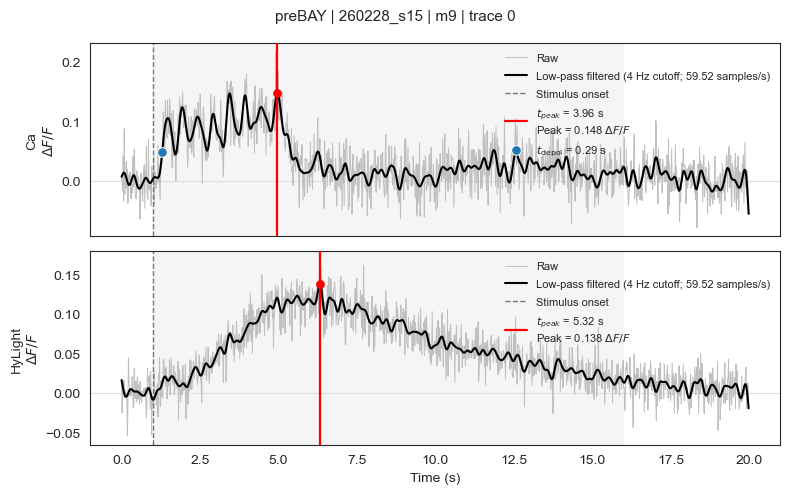

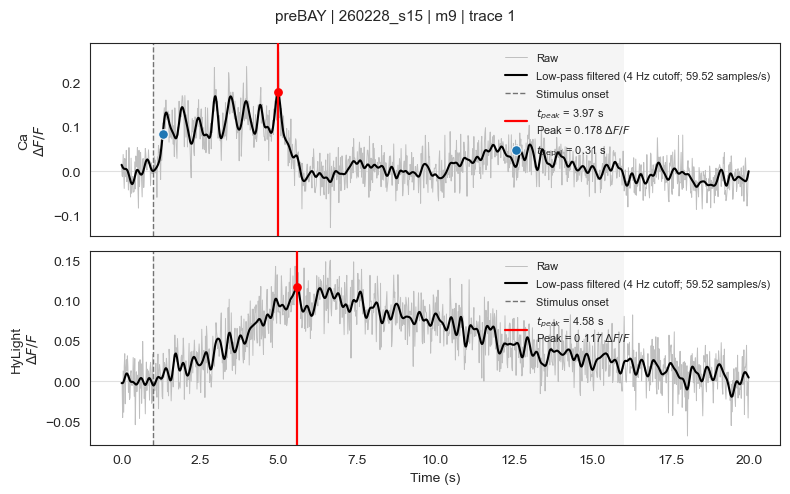

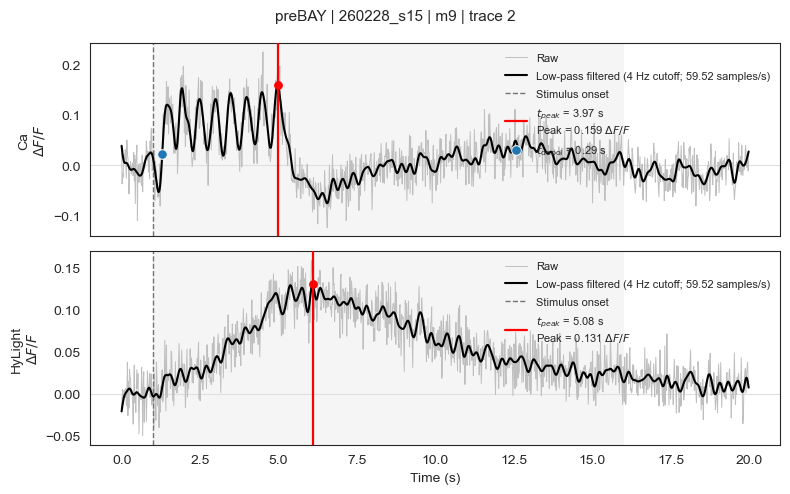

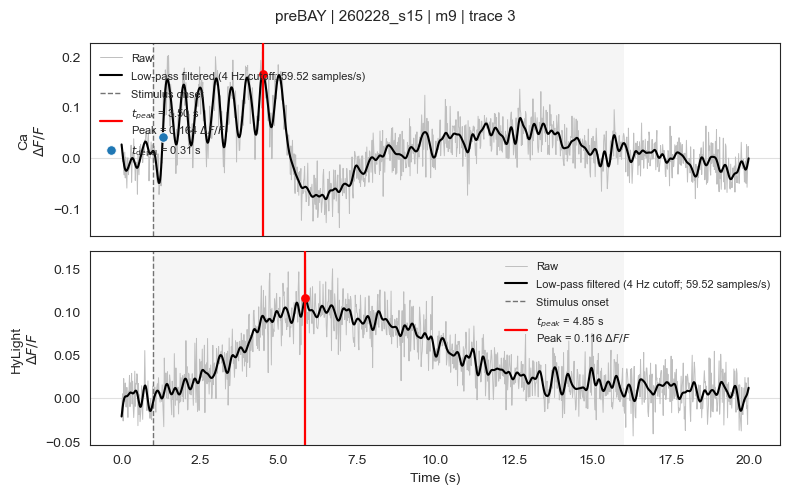

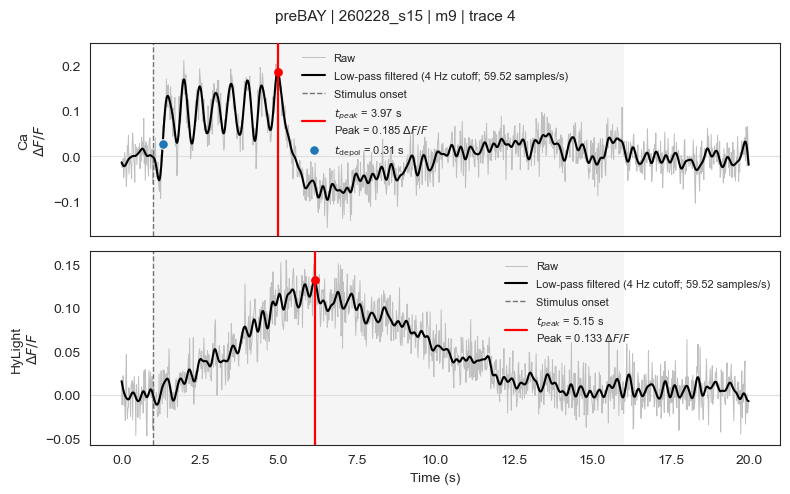

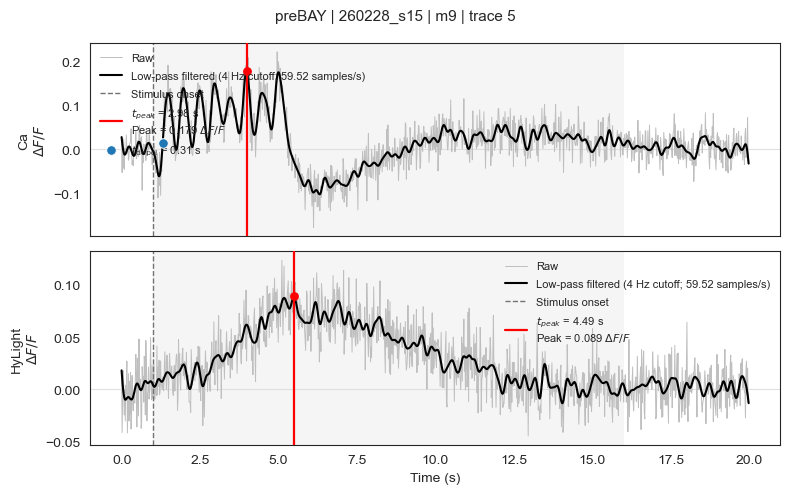

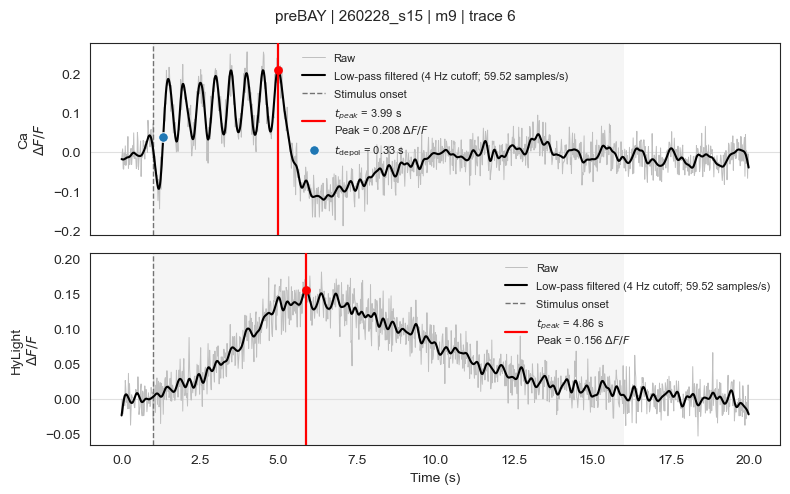


preBAY | 260302_s1 | m9
  Ca result traces: 6
  HyLight result traces: 6


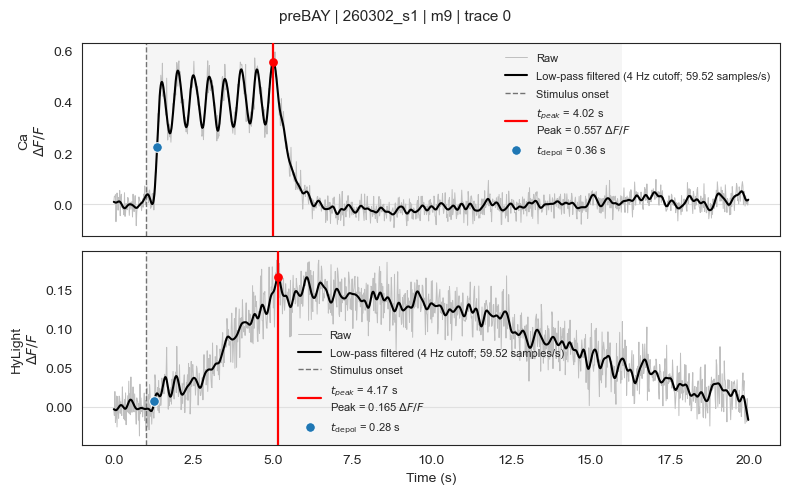

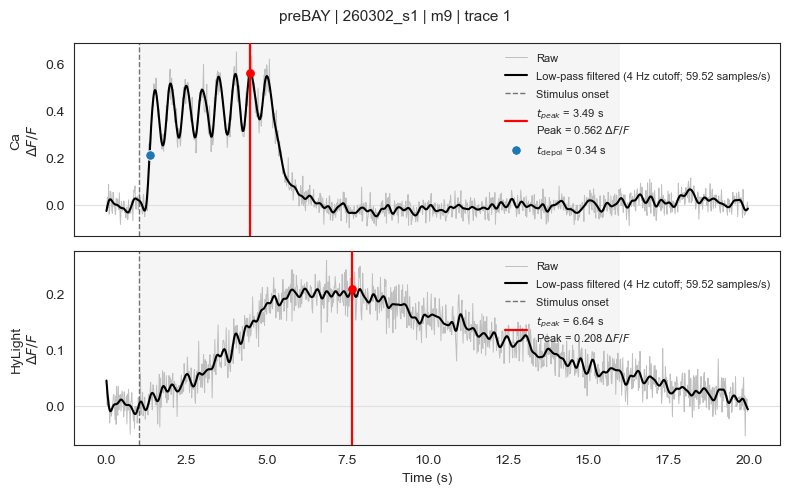

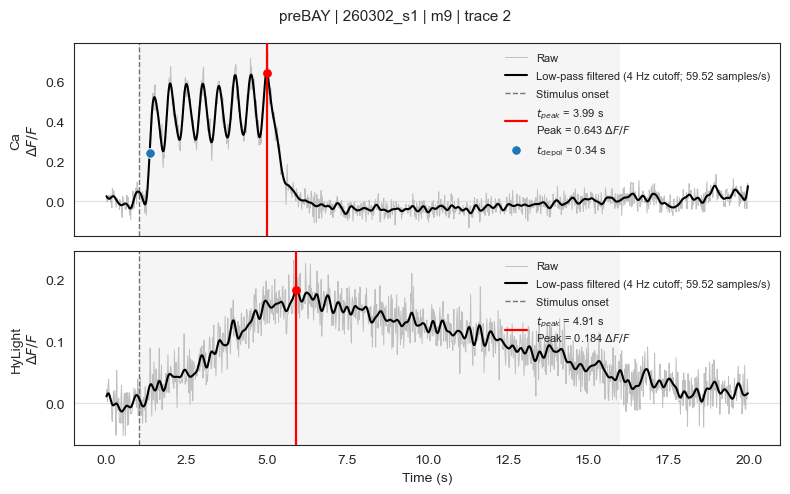

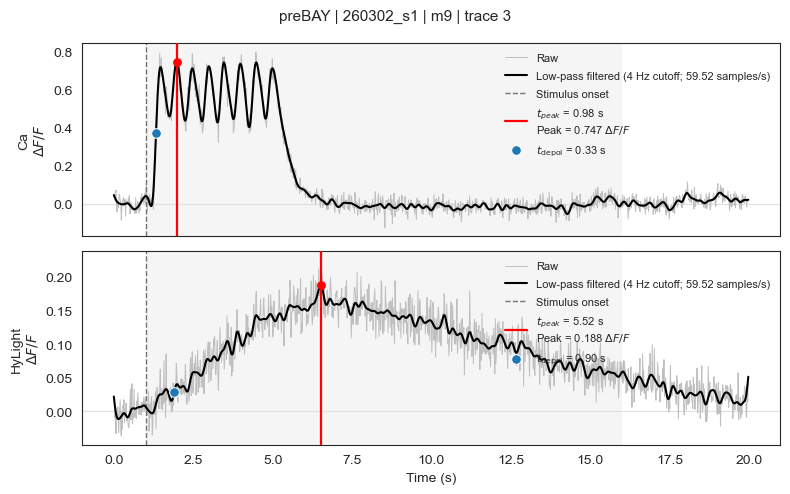

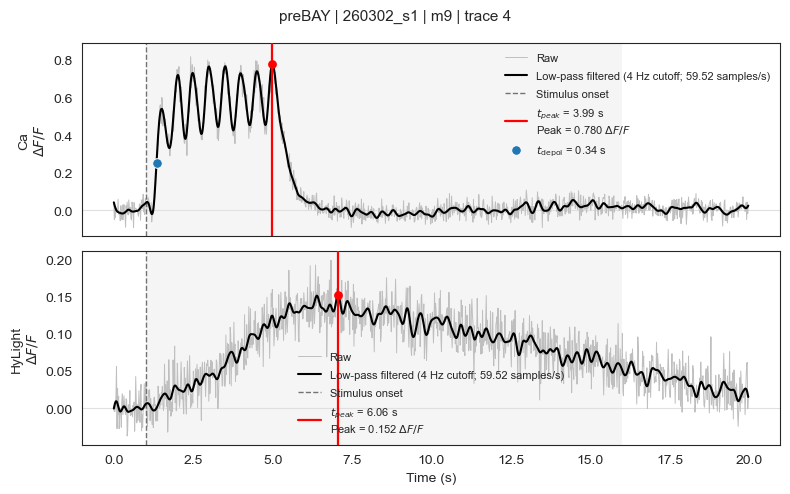

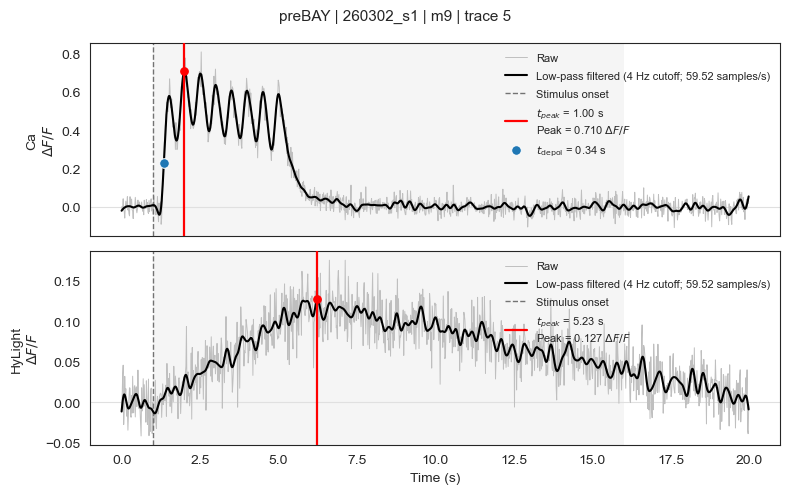


preBAY | 260302_s17 | m9
  Ca result traces: 2
  HyLight result traces: 2


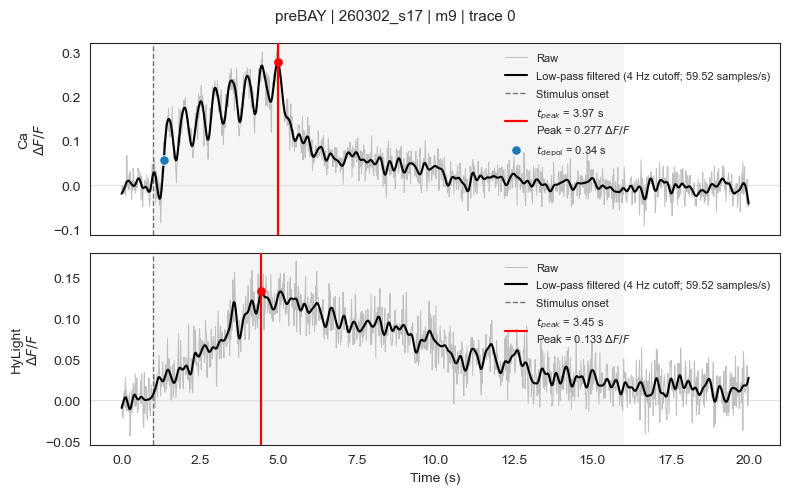

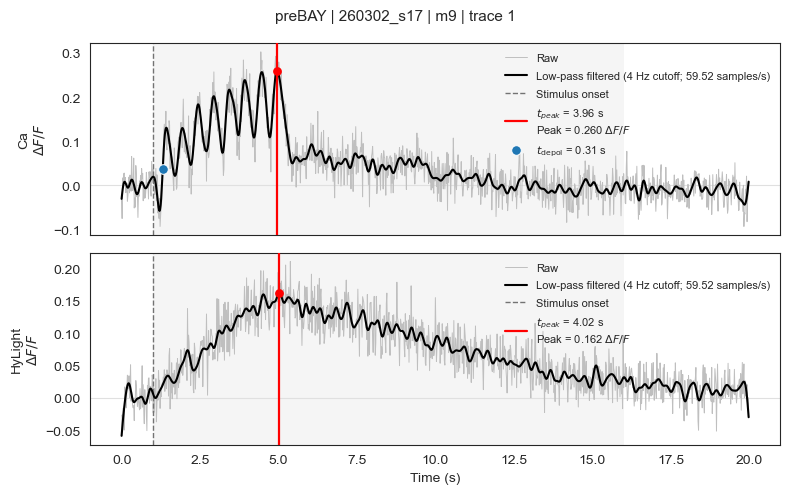


preBAY | 260302_s23 | m9
  Ca result traces: 2
  HyLight result traces: 2


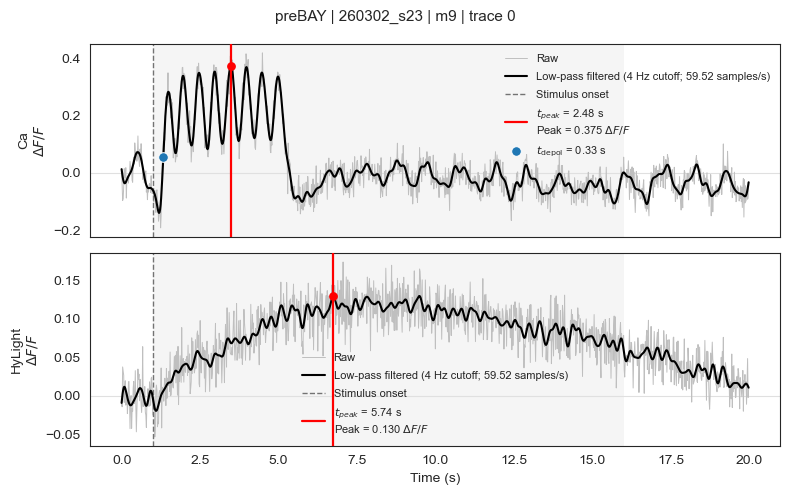

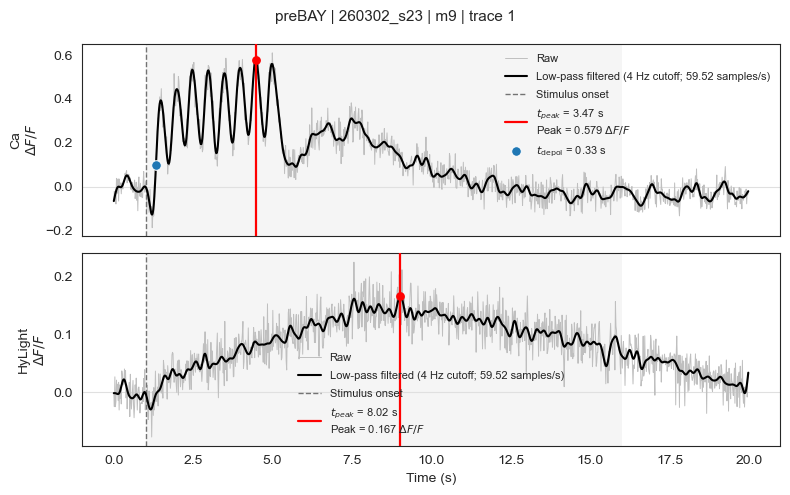


preBAY | 260302_s46 | m9
  Ca result traces: 6
  HyLight result traces: 6


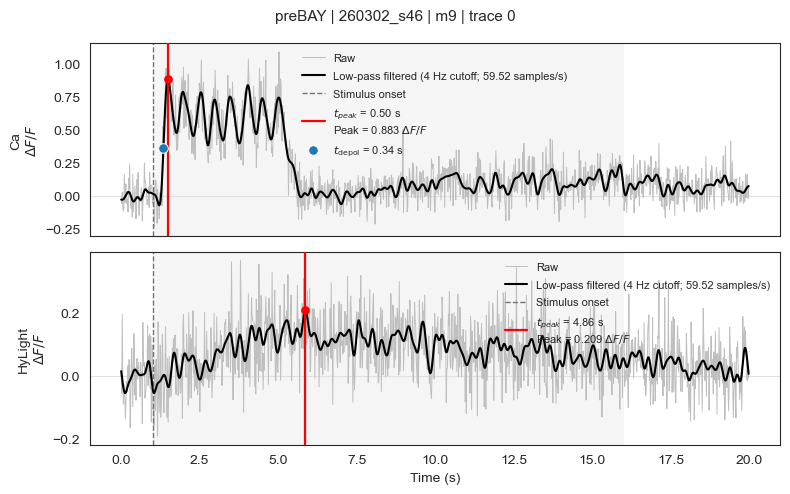

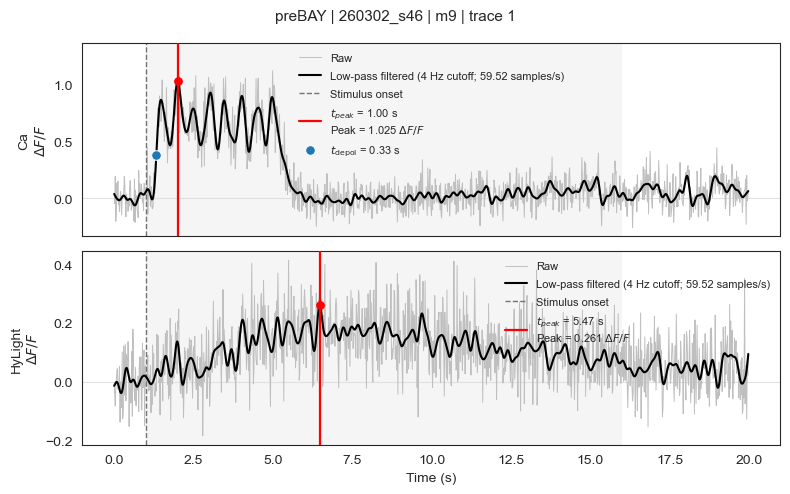

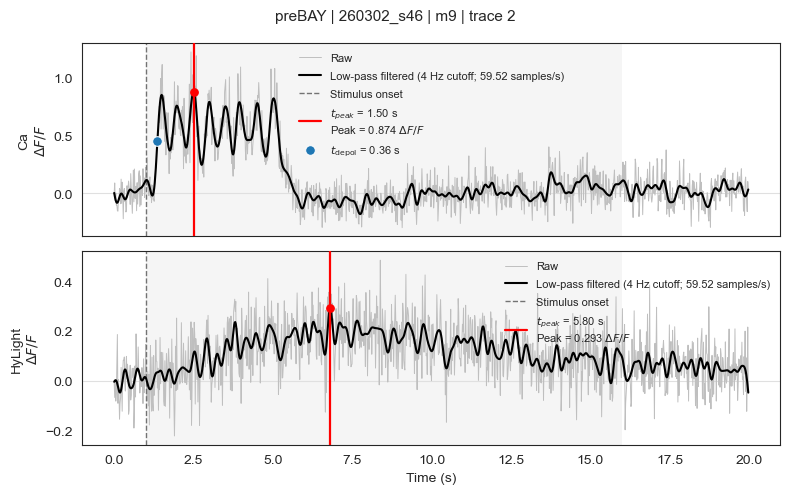


Plotted 20 paired responses.


In [55]:
plot_tpeak_sanity_checks(
    all_data,
    tpeak_results,

    # Use None to include all available values.
    genotypes=None,
    series=None,
    compartments=["m9"],

    # Use None to plot every trace.
    max_plots=20,
)

## 7. Plots
`dotplot_tpeak` plots the column given in `metric_col` for one sensor (`measurement_type`). Other columns can be plotted the same way, for example `metric_col="peak_dff"` or `metric_col="t_first_depolarization_s"`.

Ca tPeak:

In [39]:
results = dotplot_tpeak(
    tpeak_df,
    compartment="m9",
    measurement_type="ca",
    metric_col="tpeak_s",
    control_genotypes=("control", "control-RNAi"),

    
    figsize=(9.6, 2.5),
    y_limits=(0, 24),
    ylabel=r"Ca$^{2+}$ $t_{\mathrm{peak}}$ (s)",
    show_reference_line=False,
    star_x_offset=0.18,
    lowercase_xticklabels=True,
    italicize_xticklabels=True,
    show_tables=True,
)

results["summary"][["Genotype", "n", "mean", "sem"]]

HyLight tPeak:

In [56]:
results = dotplot_tpeak(
    tpeak_df,
    compartment="m9",
    measurement_type="hylight",
    metric_col="tpeak_s",
    control_genotypes=("control", "control-RNAi"),
    
    
    figsize=(9.6, 2.5),
    y_limits=(0, 16),
    ylabel=r"HyLight $t_{\mathrm{peak}}$ (s)",
    show_reference_line=False,
    star_x_offset=0.18,
    lowercase_xticklabels=True,
    italicize_xticklabels=True,
)

results["summary"][["Genotype", "n", "mean", "sem"]]

## 8. Save the tPeak table (optional)

In [57]:
# Save the tPeak table as a CSV file (set the path first).
output_path3 = "your/path/here/BAY_lowpass-4hz_tpeak_final.csv"

tpeak_df.to_csv(output_path3, index=False)
print("Saved to:", output_path3)

Saved to: your/path/here/BAY_lowpass-4hz_tpeak_final.csv
